# Exploratory Data Analysis: FinAccess 2024
**Question:** where does the gender gap in financial inclusion sit, what drives it, and how should the data be prepared for modelling?

All analysis uses adults 18+ (n = 19,750). Population rates are weighted with KNBS survey weights; descriptive statistics describe the sample (unweighted).

**Two targets** (1 = yes, 0 = no):
- `target_bank_account`: uses a traditional bank account (main modelling target)
- `target_formal_access`: uses any formal financial service (benchmark)

**Contents**
1. Data overview
2. Univariate analysis
3. Bivariate analysis
4. Multivariate analysis
5. Data preparation decisions: scaling, encoding, transformation, PCA, leakage, class imbalance
6. Feature engineering and selection
7. Conclusions


In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.config import CLEAN_FILE, REPORTS_DIR
from src.eda_utils import (set_style, weighted_rate, gender_gap, bars_by_gender, lines_by_gender,
                           profile_by_gender, dumbbell_by_gender, dumbbell_rates, heatmap_gap,
                           lollipop_gap, violin_by_gender, forest_gaps)
set_style()
NEUTRAL = "#5B7C99"          # colour for charts that are not about gender
FIG = REPORTS_DIR / "figures"
FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(CLEAN_FILE)
print(df.shape)


(19750, 49)


## 1. Data Overview

In [2]:
df.dtypes

respondent_id                       str
county                              str
cluster_id                        int64
location_type                       str
hh_head_gender                      str
age                               int64
relationship_to_hh_head             str
gender                              str
household_size                    int64
num_children                    float64
num_children_under5             float64
decides_daily_spending              str
decides_major_spending              str
skipped_meals_last_month        float64
can_read_sms                    float64
income_from_farming               int64
income_from_regular_job           int64
income_from_casual_work           int64
income_from_own_business          int64
relies_on_family_support          int64
income_last_month               float64
income_highest_month            float64
income_lowest_month             float64
phone_access_type                   str
phone_internet_capable          float64


In [3]:
# Variable groups used throughout the notebook
TARGETS = ["target_bank_account", "target_formal_access"]
CONTINUOUS = ["age", "household_size", "num_children", "num_children_under5", "num_income_sources",
              "income_last_month", "income_highest_month", "income_lowest_month",
              "income_volatility"]
ORDINAL = ["education_level", "wealth_quintile", "internet_use_frequency", "financial_literacy_score",
           "cost_to_nearest_provider", "distance_to_nearest_provider"]
BINARY = ["disability_status", "income_from_farming", "income_from_regular_job", "income_from_casual_work",
          "income_from_own_business", "relies_on_family_support", "owns_house", "owns_land",
          "has_any_id", "owns_phone", "phone_internet_capable", "can_read_sms",
          "skipped_meals_last_month", "experienced_shock"]
NOMINAL = ["location_type", "county", "livelihood_category", "marital_status", "relationship_to_hh_head",
           "decides_daily_spending", "decides_major_spending", "phone_access_type",
           "nearest_provider_type", "network_quality", "land_title_status"]

print(f"{len(CONTINUOUS)} continuous | {len(ORDINAL)} ordinal | {len(BINARY)} binary | {len(NOMINAL)} nominal")


9 continuous | 6 ordinal | 14 binary | 11 nominal


In [4]:
overview = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "missing_%": (df.isna().mean() * 100).round(1),
    "unique_values": df.nunique(),
})
print("Duplicate respondents:", df["respondent_id"].duplicated().sum())
overview.sort_values("missing_%", ascending=False).head(15)


Duplicate respondents: 0


,type,missing_%,unique_values
income_volatility,float64,11.8,742
income_lowest_month,float64,11.6,193
income_last_month,float64,10.3,231
income_highest_month,float64,6.8,279
decides_major_spending,str,2.9,3
decides_daily_spending,str,2.7,3
distance_to_nearest_provider,float64,1.9,8
cost_to_nearest_provider,float64,1.3,6
can_read_sms,float64,1.2,2
nearest_provider_type,str,1.1,3


**Finding (overview):** 

The data has 19,750 adults and 49 columns, with no duplicate respondents. 

Missing values are low overall and concentrated in the income variables: income volatility (11.8%), lowest-month income (11.6%), last-month income (10.3%) and highest-month income (6.8%), mainly respondents who did not report an income figure. 

Who decides spending is missing for about 3% (answers "Not stated", "Don't know" or refused), and every other variable is under 2% missing.

No variable needs to be dropped for missingness.

## 2. Univariate analysis
One variable at a time: how is each distributed, how spread out is it, and are there problems (skew, rare categories, missing values) that affect modelling?

### 2.1 Target variables and class imbalance

                      unweighted  weighted  majority_to_minority
target_bank_account        0.263     0.290                 2.808
target_formal_access       0.857     0.848                 5.986


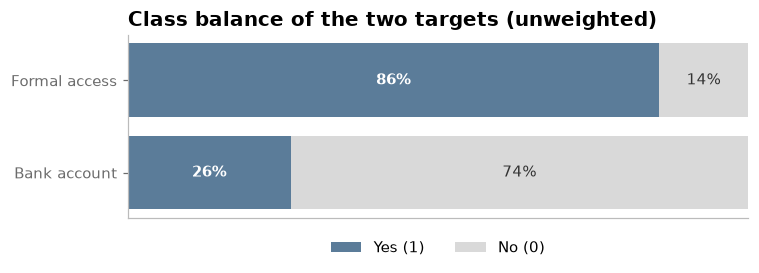

In [5]:

balance = pd.DataFrame({
    "unweighted": df[TARGETS].mean(),
    "weighted": [np.average(df[t], weights=df["survey_weight"]) for t in TARGETS],
}, index=TARGETS)
p = balance["unweighted"]
balance["majority_to_minority"] = np.maximum(p, 1 - p) / np.minimum(p, 1 - p)   # e.g. 2.8 = 2.8 "no" for every "yes"
print(balance.round(3))

fig, ax = plt.subplots(figsize=(7, 2.6))
labels = ["Bank account", "Formal access"]
ax.barh(labels, balance["unweighted"], color=NEUTRAL, label="Yes (1)")
ax.barh(labels, 1 - balance["unweighted"], left=balance["unweighted"], color="#D9D9D9", label="No (0)")
for i, v in enumerate(balance["unweighted"]):
    ax.text(v / 2, i, f"{v:.0%}", ha="center", va="center", color="white", fontweight="bold")
    ax.text(v + (1 - v) / 2, i, f"{1 - v:.0%}", ha="center", va="center", color="#333333")
ax.set_xlim(0, 1); ax.set_xticks([]); ax.grid(False)
ax.set_title("Class balance of the two targets (unweighted)")
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.05))
plt.tight_layout(); plt.savefig(FIG / "uni_class_balance.png", bbox_inches="tight"); plt.show()


**Finding (class balance):** 

Both targets are imbalanced, in opposite directions. 

For bank account use, 26% of respondents are "yes" (29.0% weighted), a majority-to-minority ratio of about 2.8 to 1: mild imbalance. 

For formal access, 86% are "yes" (84.8% weighted), so the *minority* class is the excluded 14%, a ratio of about 6 to 1: moderate imbalance.


**Implication for modelling:**

- Accuracy is misleading here: a model that always predicts "no bank account" would be 74% accurate, and one that always predicts "included" would be 86% accurate. 

So models are compared on **PR-AUC**, whose chance baseline equals the share of positives (0.26 for bank use), alongside ROC-AUC and Brier score.

- The bank-use imbalance is mild, so no resampling (SMOTE) or class weights are used; both distort predicted probabilities. 

Following the course order of remedies, imbalance is handled by **moving the decision threshold** on calibrated probabilities.

- Formal access is more imbalanced and is dominated by phone ownership, which is a further reason it serves only as a benchmark target.

### 2.2 Measures of central tendency and dispersion

Mean, median and mode show the centre; 

standard deviation and IQR show the spread; 

skewness shows asymmetry (|skew| > 1 is strongly skewed); kurtosis shows heavy tails.


In [6]:
def describe(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    return pd.Series({"n": len(s), "mean": s.mean(), "median": s.median(), "mode": s.mode().iloc[0],
                      "std": s.std(), "IQR": q3 - q1, "min": s.min(), "max": s.max(),
                      "skewness": s.skew(), "kurtosis": s.kurt()})

numbers = df[CONTINUOUS]          # income is already in KSh, straight from clean.py
desc = numbers.apply(describe).T
desc.round(2)

,n,mean,median,mode,std,IQR,min,max,skewness,kurtosis
age,19750.0,40.56,37.00,30.0,16.79,24.0,18.0,105.0,0.81,-0.06
household_size,19750.0,4.12,4.00,1.0,2.48,4.0,1.0,20.0,0.90,1.26
num_children,19750.0,3.15,3.00,0.0,2.66,4.0,0.0,19.0,0.99,1.21
num_children_under5,19750.0,0.48,0.00,0.0,0.76,1.0,0.0,10.0,1.81,4.70
num_income_sources,19750.0,1.36,1.00,1.0,0.61,1.0,1.0,7.0,1.81,3.80
income_last_month,17706.0,10682.33,5000.00,5000.0,16529.70,9500.0,100.0,200000.0,4.95,37.27
income_highest_month,18398.0,17177.08,9000.00,5000.0,28240.94,16000.0,200.0,300000.0,5.08,35.55
income_lowest_month,17464.0,6168.95,3000.00,2000.0,10258.06,6000.0,50.0,100000.0,4.33,25.78
income_volatility,17427.0,0.61,0.67,0.5,0.26,0.3,0.0,1.0,-0.78,-0.08


### 2.3 Distributions of continuous variables


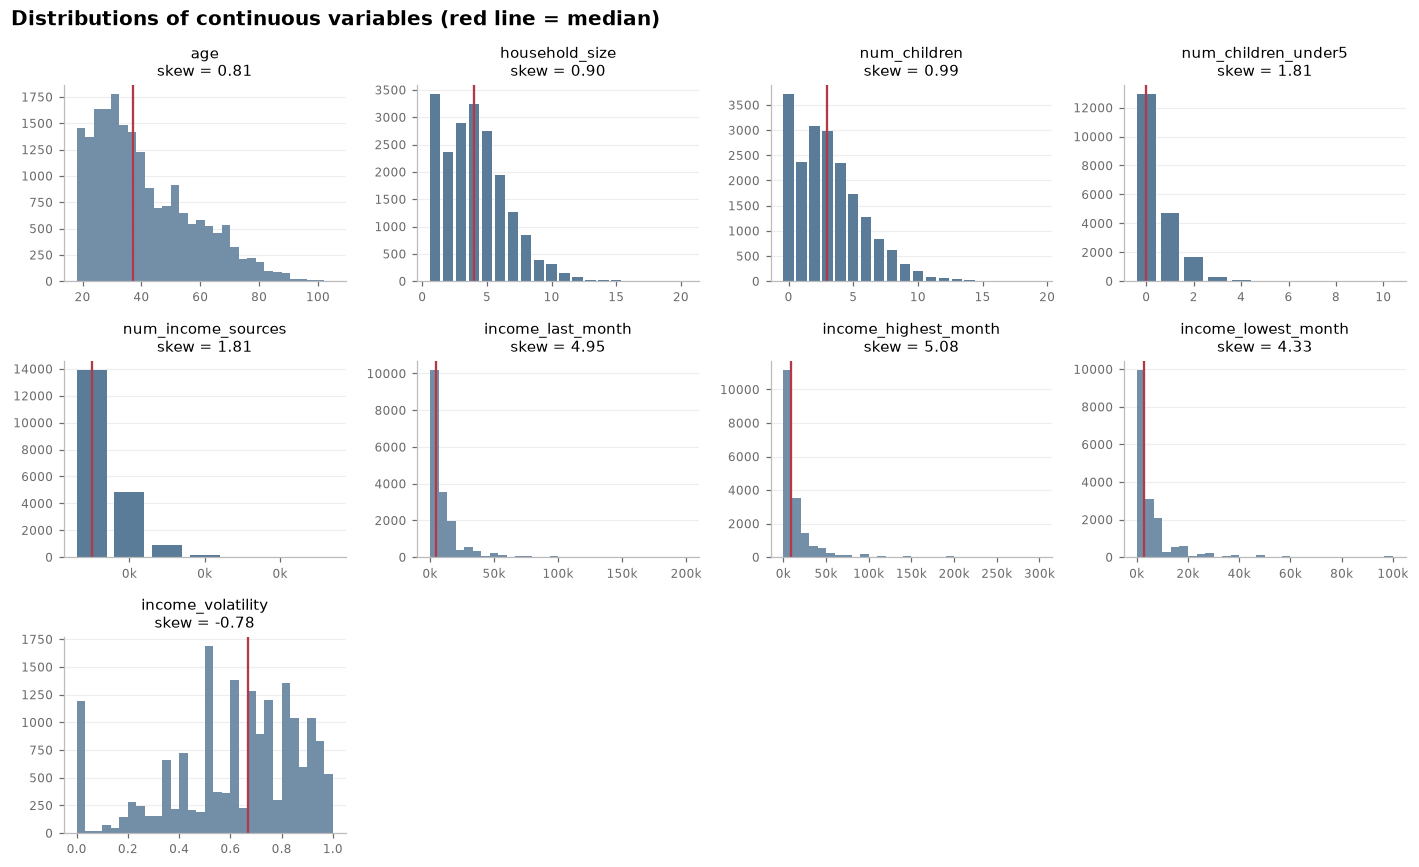

In [7]:
cols = list(numbers.columns)
fig, axes = plt.subplots(3, 4, figsize=(13, 8))
for ax, col in zip(axes.flat, cols):
    s = numbers[col].dropna()
    if s.nunique() <= 20:                       # counts (e.g. children): one bar per value
        counts = s.value_counts().sort_index()
        ax.bar(counts.index, counts.values, color=NEUTRAL, width=0.8)
    else:                                       # truly continuous: histogram
        ax.hist(s, bins=30, color=NEUTRAL, alpha=0.85)
    ax.axvline(s.median(), color="#B23A48", lw=1.5)
    ax.set_title(f"{col}\nskew = {s.skew():.2f}", fontsize=9.5, fontweight="normal", loc="center")
    if "income" in col and "volatility" not in col:
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))

    ax.tick_params(labelsize=8); ax.grid(axis="y", color="#EEEEEE")
for ax in axes.flat[len(cols):]:
    ax.axis("off")
fig.suptitle("Distributions of continuous variables (red line = median)", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "uni_histograms.png", bbox_inches="tight"); plt.show()



**Finding (distributions):**

- **Income (last, highest and lowest month) is L-shaped:** 

    Most respondents earn under KSh 20,000 a month, with a long thin tail to KSh 100,000–300,000. 
    The bulk of the data is squeezed into the first two or three bars, which is why a transformation is needed.

- **Income volatility is spiky, not smooth.** 

    About 1,200 respondents have a volatility of 0 (the same income every month, typically salaried workers), and there are sharp peaks at 0.5, 0.6, 0.67, 0.75 and 0.8. These peaks come from **round-number reporting**: people report incomes such as KSh 5,000 and 10,000, so ratios like 5,000 / 10,000 = 0.5 recur. This is a known feature of self-reported survey income, not an error.

- **Age** peaks between 25 and 35 and tails off steadily to 105, a typical adult population shape (moderate right skew, 0.81).

- **Household size** is most often 1 to 5 people; single-person households are common (about 3,400 respondents).

- **Children:** the most common answer is 0, and most respondents have no child under five. Few households have more than 10 children.

- **Income sources:** about 70% of respondents have one source of income, and very few have more than three.

**Implication:** only income needs a transformation. Volatility is bounded between 0 and 1 and is used as it is, and the count variables are left untransformed because they are bounded and only moderately skewed.

### 2.4 Yes/no variables

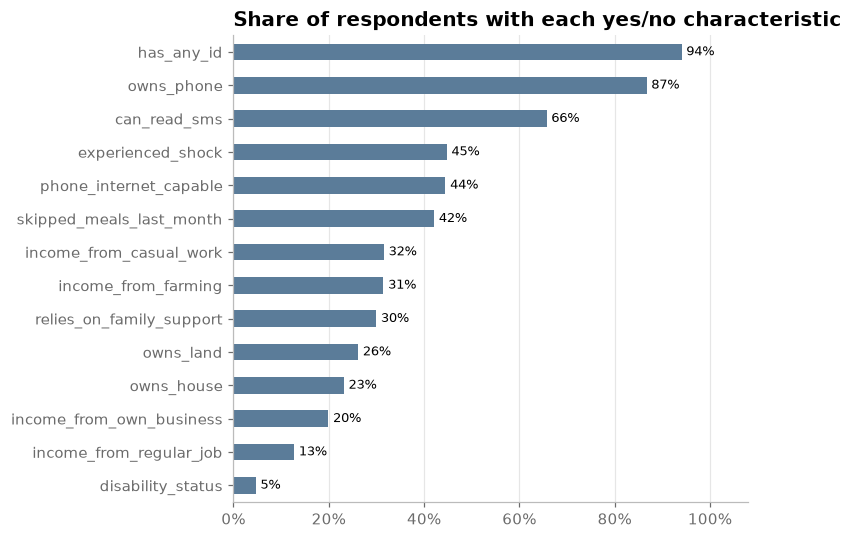

In [8]:
shares = df[BINARY].mean().sort_values()
ax = shares.plot.barh(figsize=(7, 5), color=NEUTRAL)
for i, v in enumerate(shares):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=8.5)
ax.set_xlim(0, 1.08)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="y", visible=False)
ax.set_title("Share of respondents with each yes/no characteristic")
plt.tight_layout(); plt.savefig(FIG / "uni_binary_shares.png", bbox_inches="tight"); plt.show()

**Finding (yes/no variables):**

- **Near-universal access:** 94% of respondents have an ID and 87% own a phone. These are the basic preconditions for formal finance, and their high coverage explains why formal access is so high (86%). Because so few people lack them, they separate bank users from non-users less than one might expect.

- **Vulnerability is widespread:** 45% experienced a shock in the past year and 42% skipped meals in the past month.

- **Livelihoods are mostly informal:** casual work (32%), farming (31%) and running a business (20%) are far more common than a regular salaried job (13%). 30% rely on support from family or a spouse.

- **Assets are held by a minority:** 26% own land and 23% own a house.

- **Digital capability is split:** 66% passed the SMS reading test, and 44% have an internet-capable phone.

- **Rare characteristics:** only 5% report a disability, so estimates for this group are less precise.

**Implication for modelling:** every binary variable has enough variation to be useful (none is above 95% or below 5% apart from disability, at the edge). Salaried work is uncommon (13%) but expected to be a strong predictor of bank use, because salaries are often paid into bank accounts.

### 2.5 Categorical and ordinal variables


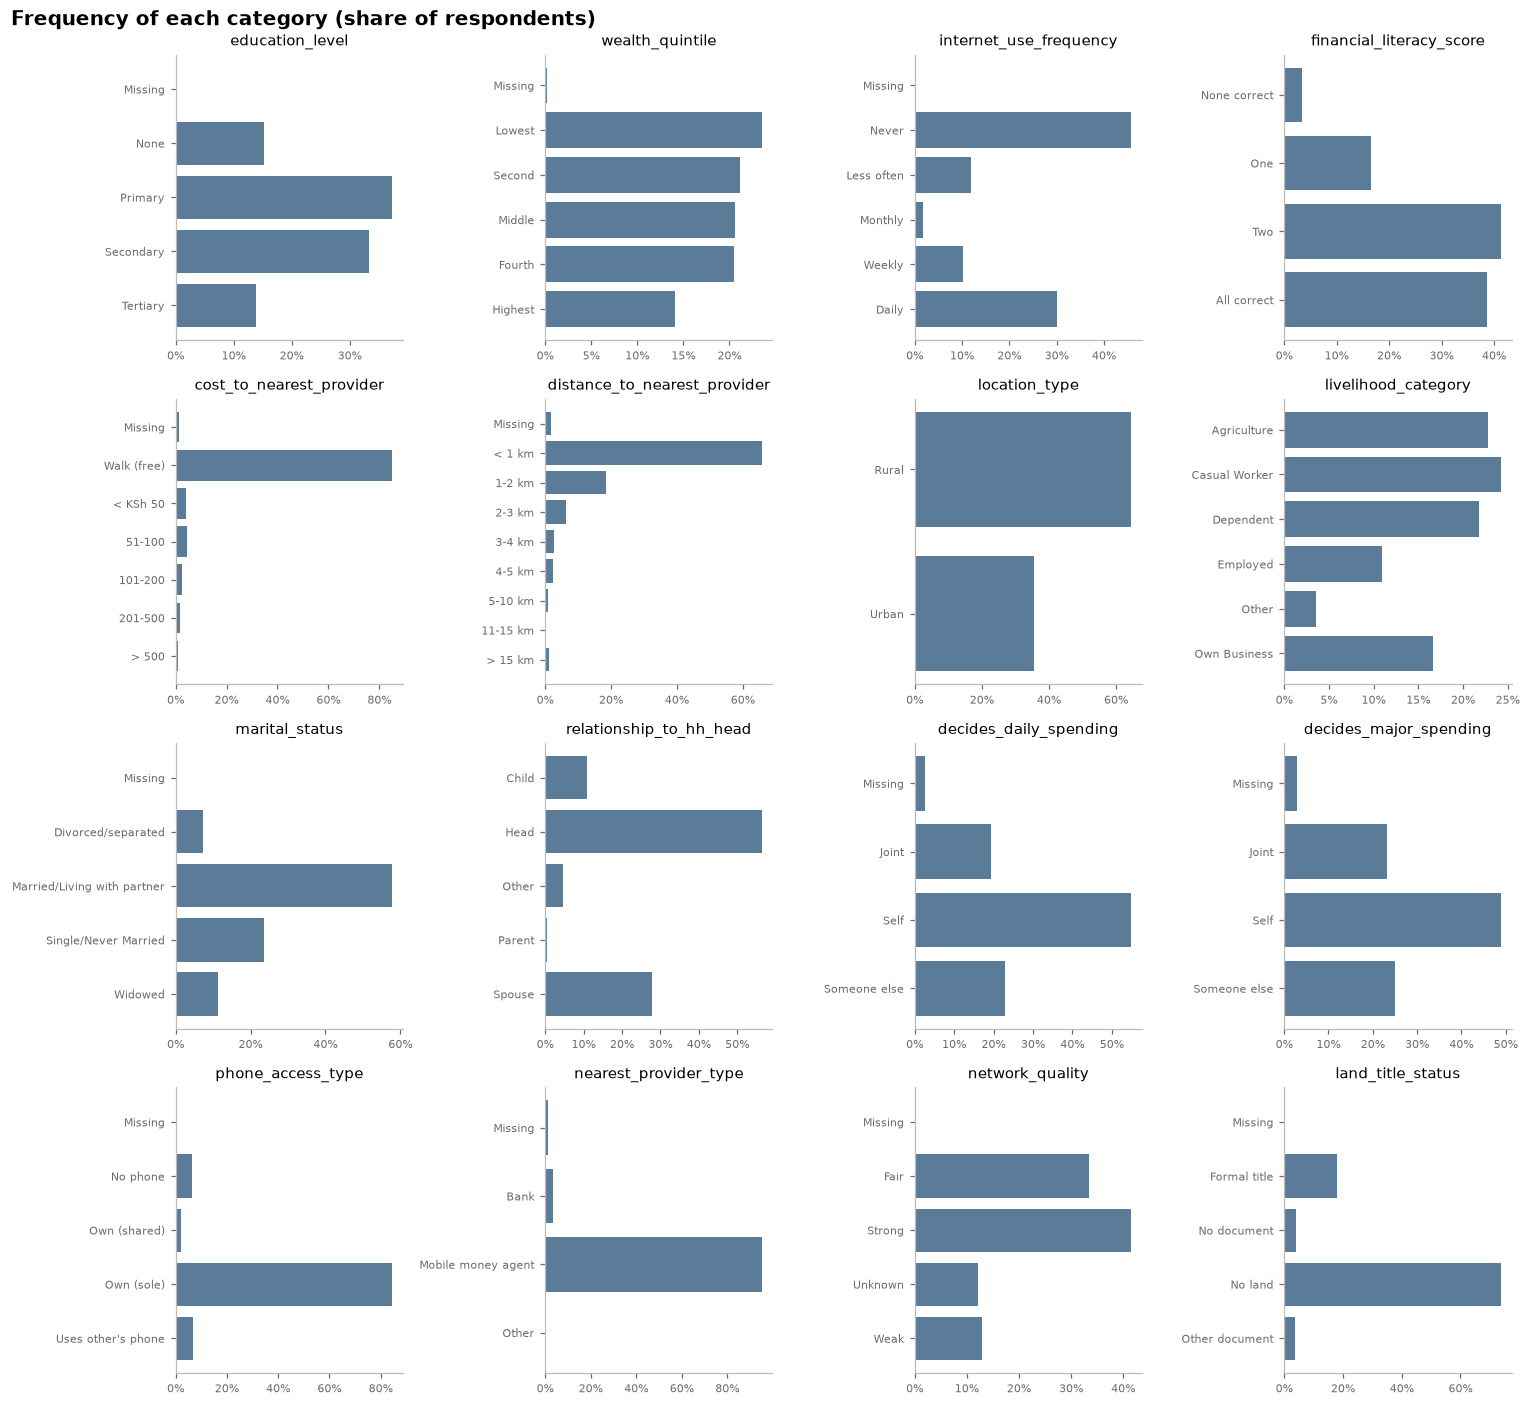

In [9]:
# readable names for the ordinal codes created in clean.py
LABELS = {
    "education_level": {0: "None", 1: "Primary", 2: "Secondary", 3: "Tertiary"},
    "wealth_quintile": {1: "Lowest", 2: "Second", 3: "Middle", 4: "Fourth", 5: "Highest"},
    "internet_use_frequency": {0: "Never", 1: "Less often", 2: "Monthly", 3: "Weekly", 4: "Daily"},
    "financial_literacy_score": {0: "None correct", 1: "One", 2: "Two", 3: "All correct"},
    "cost_to_nearest_provider": {0: "Walk (free)", 1: "< KSh 50", 2: "51-100", 3: "101-200",
                                 4: "201-500", 5: "> 500"},
    "distance_to_nearest_provider": {0: "< 1 km", 1: "1-2 km", 2: "2-3 km", 3: "3-4 km",
                                     4: "4-5 km", 5: "5-10 km", 6: "11-15 km", 7: "> 15 km"},
}
cat_cols = ORDINAL + [c for c in NOMINAL if c != "county"]   # county has 47 levels: shown in the bivariate section
fig, axes = plt.subplots(4, 4, figsize=(14, 13))
for ax, col in zip(axes.flat, cat_cols):
    freq = df[col].value_counts(normalize=True, dropna=False).sort_index(ascending=False)
    names = LABELS.get(col, {})
    freq.index = freq.index.map(lambda v: "Missing" if pd.isna(v) else names.get(v, str(v)))
    ax.barh(freq.index, freq.values, color=NEUTRAL)
    ax.set_title(col, fontsize=9.5, fontweight="normal", loc="center")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.tick_params(labelsize=7.5); ax.grid(axis="y", visible=False)
for ax in axes.flat[len(cat_cols):]:
    ax.axis("off")
fig.suptitle("Frequency of each category (share of respondents)", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "uni_categorical.png", bbox_inches="tight"); plt.show()


**Finding (categorical and ordinal variables):**

- **Education:** most respondents have primary (about 37%) or secondary (about 33%) education; 15% have none and 14% tertiary.

- **Wealth quintiles are not equal in the sample** (about 24% lowest vs 14% highest), because quintiles are defined for the population, and the unweighted sample contains more poorer, rural households. Survey weights correct for this in population estimates.

- **Location and livelihood:** about two-thirds of respondents are rural. Livelihoods are spread across casual work, agriculture and dependence (22–24% each), with own business at 17% and formal employment at 11%.

- **Household position:** 56% are household heads and 28% spouses; 58% are married.

- **Financial agency:** 55% decide their own daily spending, 19% decide jointly and 23% say someone else decides.

- **Digital access is polarised:** 46% never use the internet while 30% use it daily; only about 2% use it monthly. 84% have a phone for their own use.

- **Physical access is near-universal:** 85% can walk to their nearest provider at no cost, 65% live under 1 km away, and for 95% the nearest provider is a mobile money agent (a bank for only 3%).

- **Land:** 74% own no land; 18% hold a formal title.

- **Financial literacy is fairly high:** about 79% answered two or all three questions correctly.

**Implications for modelling:**

1. **Low-variation variables:** cost to provider (85% "walk"), nearest provider type (95% mobile money agent) and phone access (84% own phone) are dominated by one category, so they carry limited information. They are kept but are candidates for removal in feature selection.

2. **Rare categories:** some levels have very few people (e.g. "Parent" in relationship to head, "Own (shared)" phone, "Other" provider, "Monthly" internet use). The one-hot encoder's `min_frequency=30` setting merges such levels into an "infrequent" group, so the model does not learn from tiny groups.

3. **Encoding:** education, wealth, internet use, financial literacy, cost and distance are ordered, so they are kept as ordered numbers (ordinal encoding); the remaining categories have no natural order and are one-hot encoded.

4. **Missing values** are below 3% in every categorical variable and are treated as an "UNKNOWN" category in the pipeline.

## 3. Bivariate analysis
Each variable against the target, split by gender. Weighted rates with 95% confidence intervals.

## 3.1. The gender gap is small for formal access but large for bank use

In [10]:
both = df.melt(id_vars=["gender", "survey_weight"],
               value_vars=["target_formal_access", "target_bank_account"],
               var_name="target", value_name="used")
both["target"] = both["target"].map({"target_formal_access": "Formal access",
                                     "target_bank_account": "Bank account"})

weighted_rate(both, "used", ["target", "gender"]).round(3)

,target,gender,rate,low,high,n
0,Bank account,Female,0.225,0.213,0.237,11739
1,Bank account,Male,0.359,0.343,0.374,8011
2,Formal access,Female,0.840,0.830,0.851,11739
3,Formal access,Male,0.857,0.846,0.868,8011


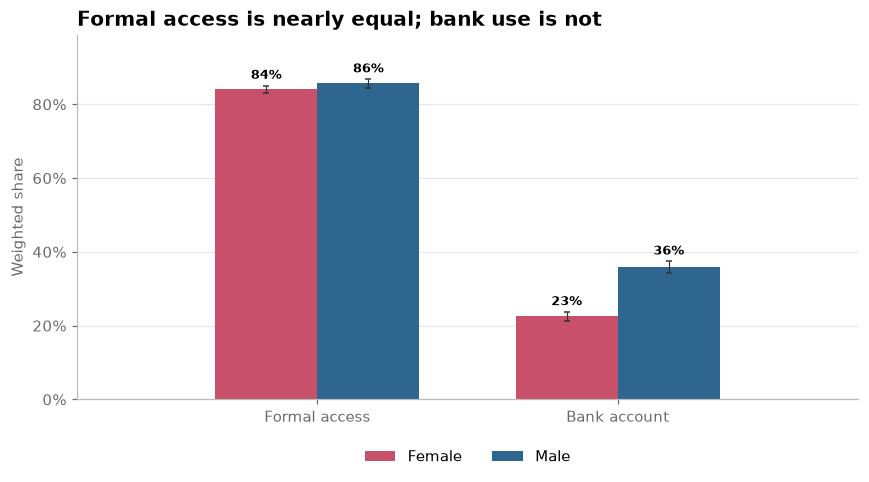

In [11]:
bars_by_gender(both, "used", "target", order=["Formal access", "Bank account"],
               title="Formal access is nearly equal; bank use is not",
               fname=FIG / "h1_gap_by_target.png")
plt.show()

**Finding:** 

Formal access is nearly equal for women (84.0%) and men (85.7%); the confidence intervals overlap. 

Bank use is not: 22.5% of women vs 35.9% of men, a **13.4-point gap** with non-overlapping intervals. The gender gap in inclusion now sits mainly in traditional banking.

## Sample profile: how do women and men differ on the drivers of inclusion?

In [12]:
profile = {
    "Lives in an urban area":          df["location_type"].eq("Urban"),
    "Secondary education or higher":   df["education_level"].ge(2),
    "In the top two wealth quintiles": df["wealth_quintile"].ge(4),
    "Earns from a regular job":        df["income_from_regular_job"].eq(1),
    "Runs own business":               df["income_from_own_business"].eq(1),
    "Relies on family support":        df["relies_on_family_support"].eq(1),
    "Owns land":                       df["owns_land"].eq(1),
    "Holds a formal land title":       df["land_title_status"].eq("Formal title"),
    "Has an ID":                       df["has_any_id"].eq(1),
    "Owns a phone":                    df["owns_phone"].eq(1),
    "Has an internet-capable phone":   df["phone_internet_capable"].eq(1),
    "Decides own daily spending":      df["decides_daily_spending"].eq("Self"),
}
prof = profile_by_gender(df, profile)
prof.round(3)

gender,Female,Male,gap_pts
characteristic,,,
Relies on family support,0.404,0.208,-19.558
Runs own business,0.222,0.183,-3.949
Has an ID,0.919,0.919,-0.005
Owns a phone,0.868,0.873,0.491
In the top two wealth quintiles,0.417,0.427,1.063
Lives in an urban area,0.411,0.423,1.154
Holds a formal land title,0.134,0.186,5.216
Secondary education or higher,0.518,0.590,7.265
Owns land,0.198,0.274,7.567


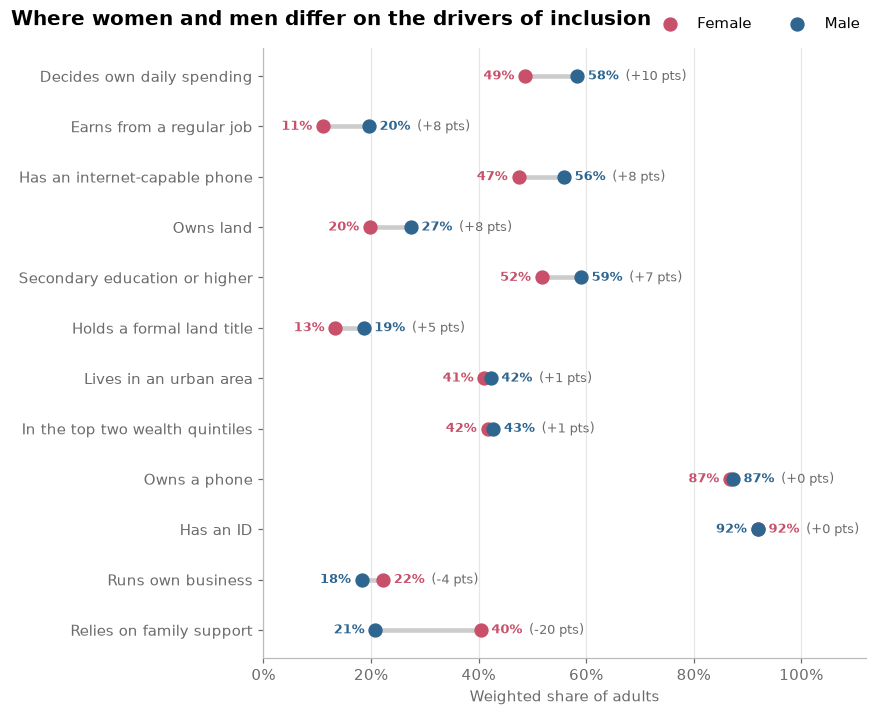

In [13]:
dumbbell_by_gender(prof, "Where women and men differ on the drivers of inclusion",
                   fname=FIG / "profile_by_gender.png")
plt.show()

**Finding (sample profile):** 

Women and men are similar on household-level measures (wealth quintile, urban residence) and on basic access (ID, phone ownership). 

The gaps are in individual resources and agency: women are twice as likely to rely on family support (40% vs 21%) and less likely to have a regular job (11% vs 20%), own land (20% vs 27%), hold a formal title (13% vs 19%), have an internet-capable phone (47% vs 56%), or decide their own daily spending (49% vs 58%). 

The bank gap is therefore likely driven by individual economic resources, not household poverty.

## 3.2. Does the bank gap narrow with education and wealth?

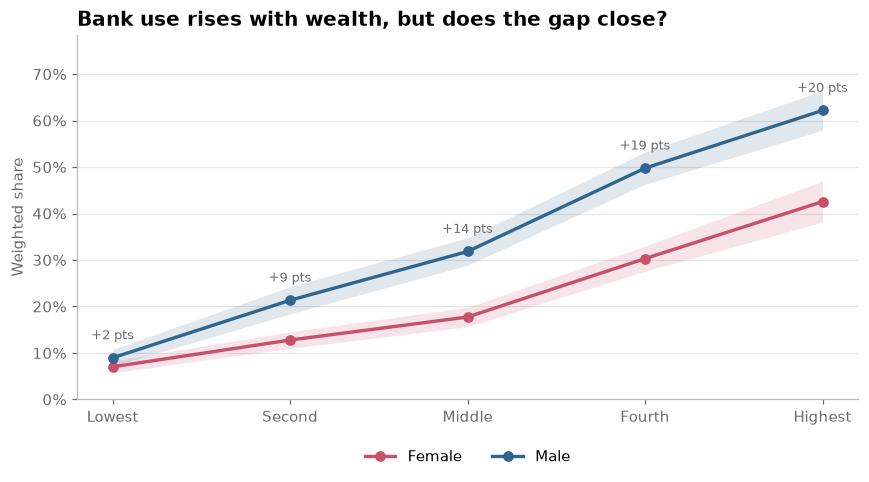

gender,Female,Male,gap_pts
wealth_quintile,,,
1.0,0.070,0.089,1.935
2.0,0.128,0.213,8.559
3.0,0.177,0.318,14.100
4.0,0.303,0.498,19.459
5.0,0.426,0.622,19.623


In [14]:
lines_by_gender(df, "target_bank_account", "wealth_quintile",
                title="Bank use rises with wealth, but does the gap close?",
                xlabels=["Lowest", "Second", "Middle", "Fourth", "Highest"],
                fname=FIG / "h2_bank_by_wealth.png")
plt.show()
gender_gap(df, "target_bank_account", "wealth_quintile").round(3)

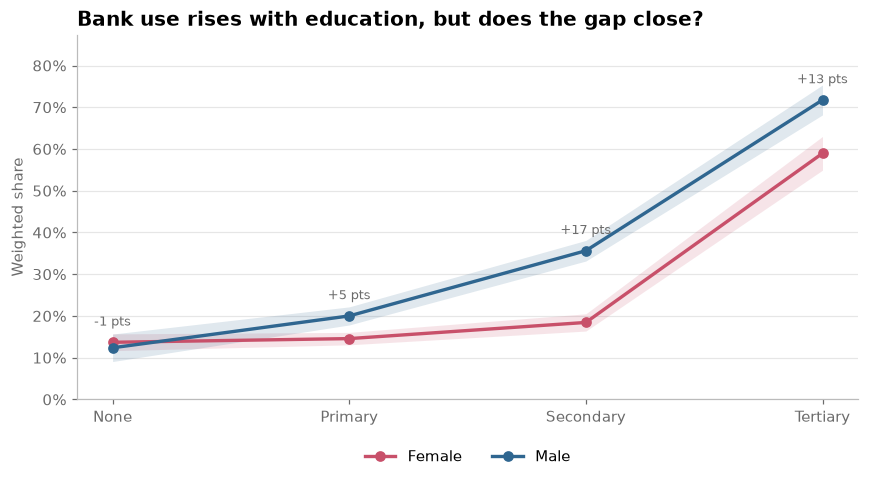

gender,Female,Male,gap_pts
education_level,,,
0.0,0.137,0.124,-1.319
1.0,0.146,0.200,5.433
2.0,0.184,0.356,17.181
3.0,0.590,0.717,12.785


In [15]:
lines_by_gender(df, "target_bank_account", "education_level",
                title="Bank use rises with education, but does the gap close?",
                xlabels=["None", "Primary", "Secondary", "Tertiary"],
                fname=FIG / "h2_bank_by_education.png")
plt.show()
gender_gap(df, "target_bank_account", "education_level").round(3)

**Finding** 

The bank gap does not close with wealth or education; it widens. Across wealth quintiles the gap grows from 2 pts (lowest) to 20 pts (highest), and among secondary-educated adults it reaches 17 pts. 

Women's bank use barely rises until tertiary level. Because wealth is measured at household level, this suggests household resources translate into men's accounts more than women's, so individual income and financial control matter more than household poverty.

## 3.3. Income and livelihood: at the same income, is bank use equal?

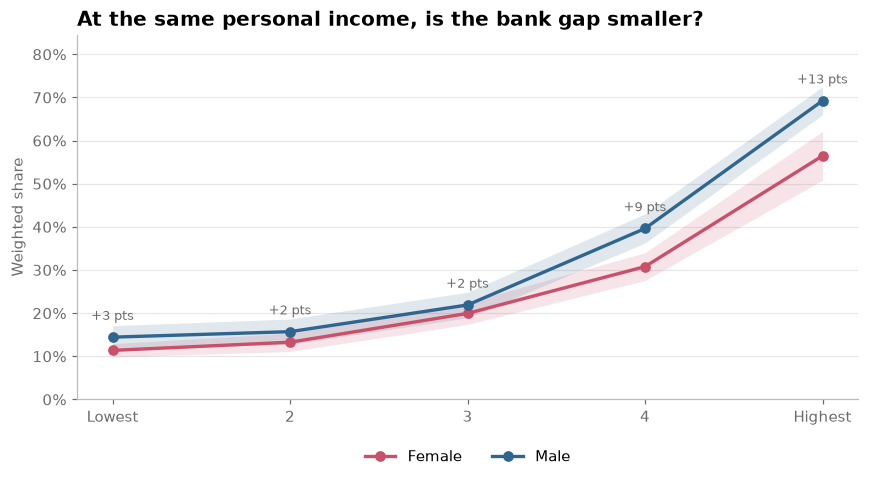

gender,Female,Male,gap_pts
income_band,,,
1.0,0.114,0.144,3.063
2.0,0.133,0.157,2.448
3.0,0.199,0.219,1.953
4.0,0.308,0.396,8.838
5.0,0.565,0.692,12.776


In [16]:
df["income_band"] = pd.qcut(df["income_last_month"], 5, labels=False) + 1   # 1 = lowest 20%

lines_by_gender(df.dropna(subset=["income_band"]), "target_bank_account", "income_band",
                title="At the same personal income, is the bank gap smaller?",
                xlabels=["Lowest", "2", "3", "4", "Highest"],
                fname=FIG / "h3_bank_by_income.png")
plt.show()
gender_gap(df, "target_bank_account", "income_band").round(3)

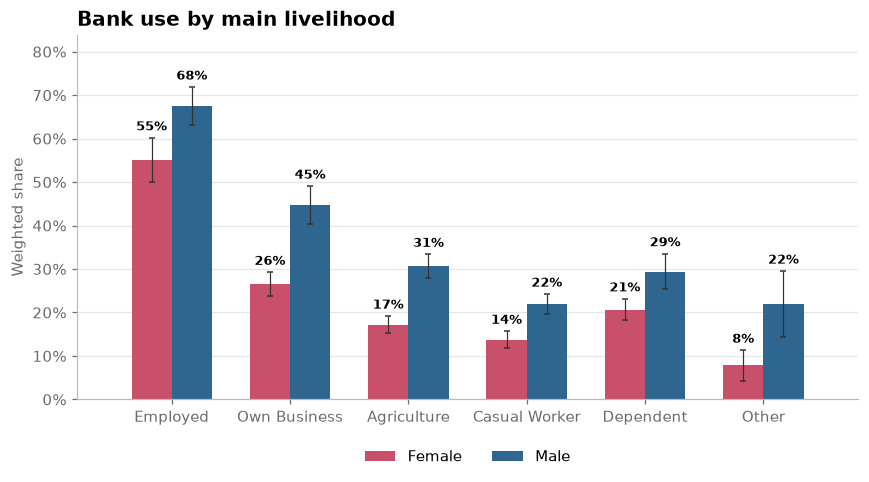

gender,Female,Male,gap_pts
livelihood_category,,,
Agriculture,0.172,0.307,13.479
Casual Worker,0.137,0.219,8.249
Dependent,0.207,0.294,8.768
Employed,0.552,0.675,12.355
Other,0.078,0.219,14.085
Own Business,0.265,0.448,18.265


In [17]:
bars_by_gender(df, "target_bank_account", "livelihood_category",
               order=["Employed", "Own Business", "Agriculture", "Casual Worker", "Dependent", "Other"],
               title="Bank use by main livelihood",
               fname=FIG / "h3_bank_by_livelihood.png")
plt.show()
gender_gap(df, "target_bank_account", "livelihood_category").round(3)

**Finding (H3):** 

Personal income explains much of the bank gap: in the bottom three income bands the gap is only 2–3 pts with overlapping intervals, compared with 9–13 pts in the top two bands. 

When women and men earn the same, they mostly bank the same. women are concentrated in lower bands, which drives much of the overall gap.

A gap remains within every livelihood group, widest among business owners (26% of women vs 45% of men) and farmers (17% vs 31%), suggesting women's enterprises are smaller and less formal, so they rely on mobile money rather than banks.

Personal income, not household wealth, is the stronger explanation.

## 3.4- 3.5. Assets and control: land title and financial decision-making

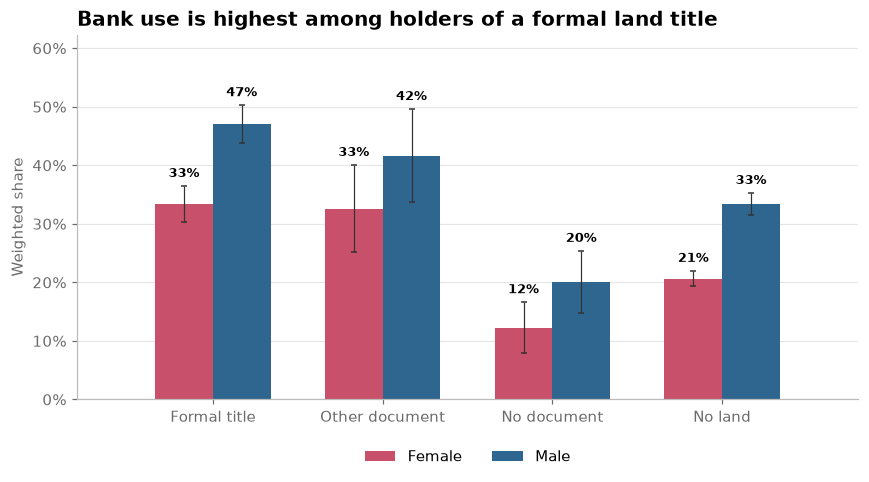

gender,Female,Male,gap_pts
land_title_status,,,
Formal title,0.333,0.470,13.688
No document,0.122,0.201,7.835
No land,0.206,0.334,12.778
Other document,0.326,0.416,9.020


In [18]:
bars_by_gender(df, "target_bank_account", "land_title_status",
               order=["Formal title", "Other document", "No document", "No land"],
               title="Bank use is highest among holders of a formal land title",
               fname=FIG / "h4_bank_by_land_title.png")
plt.show()
gender_gap(df, "target_bank_account", "land_title_status").round(3)

**Finding :** 

People with a formal land title bank the most, and people with land but no document bank the least. But at every level, women trail men by 8–14 pts. 

Women with a title bank at the same rate as men with no land (33%).

A title deed helps, but it does not close the gap on its own.

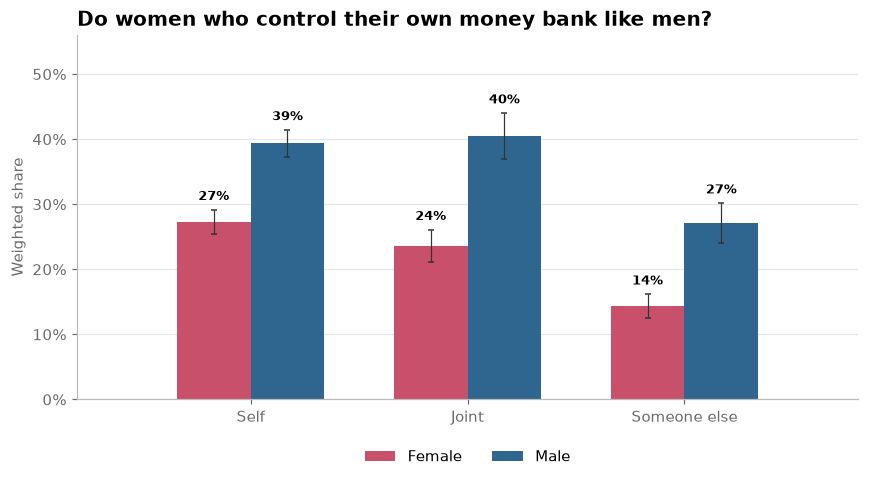

gender,Female,Male,gap_pts
decides_daily_spending,,,
Joint,0.236,0.405,16.895
Self,0.273,0.394,12.062
Someone else,0.143,0.271,12.766


In [19]:
bars_by_gender(df, "target_bank_account", "decides_daily_spending",
               order=["Self", "Joint", "Someone else"],
               title="Do women who control their own money bank like men?",
               fname=FIG / "h5_bank_by_decision.png")
plt.show()
gender_gap(df, "target_bank_account", "decides_daily_spending").round(3)

**Finding :** 

Women who decide their own spending bank almost twice as often (27%) as women whose spending is decided by someone else (14%). But they still trail men who decide for themselves (39%). 

The widest gap is in joint decisions (24% vs 40%).

Financial control matters for women, but when couples decide together, the bank account is usually in the man's name.

## 3.6. Digital access: phone ownership, sharing and smartphones

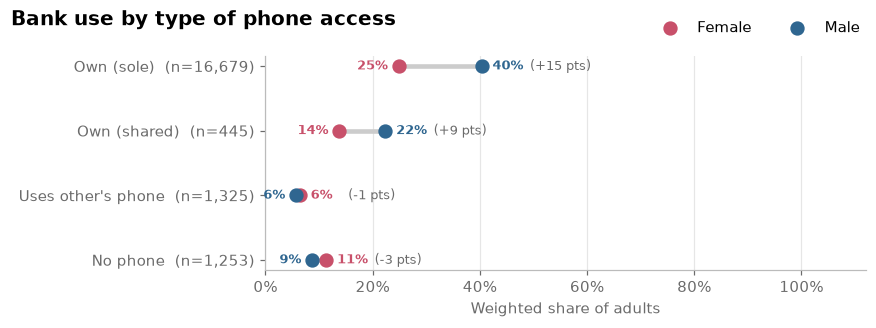

In [20]:
dumbbell_rates(df, "target_bank_account", "phone_access_type",
               order=["Own (sole)", "Own (shared)", "Uses other's phone", "No phone"],
               title="Bank use by type of phone access",
               fname=FIG / "h6_bank_by_phone_access.png")
plt.show()

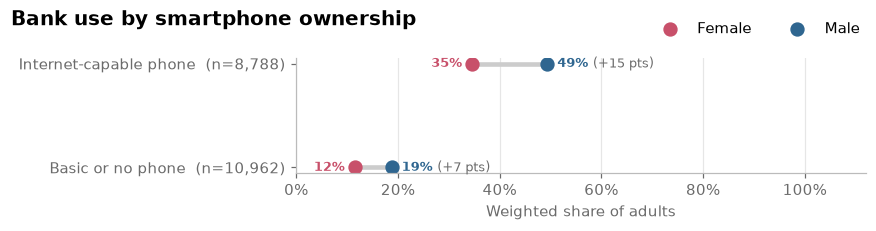

In [21]:
df["smartphone"] = df["phone_internet_capable"].map({1: "Internet-capable phone", 0: "Basic or no phone"})

dumbbell_rates(df, "target_bank_account", "smartphone",
               order=["Internet-capable phone", "Basic or no phone"],
               title="Bank use by smartphone ownership",
               fname=FIG / "h6_bank_by_smartphone.png")
plt.show()

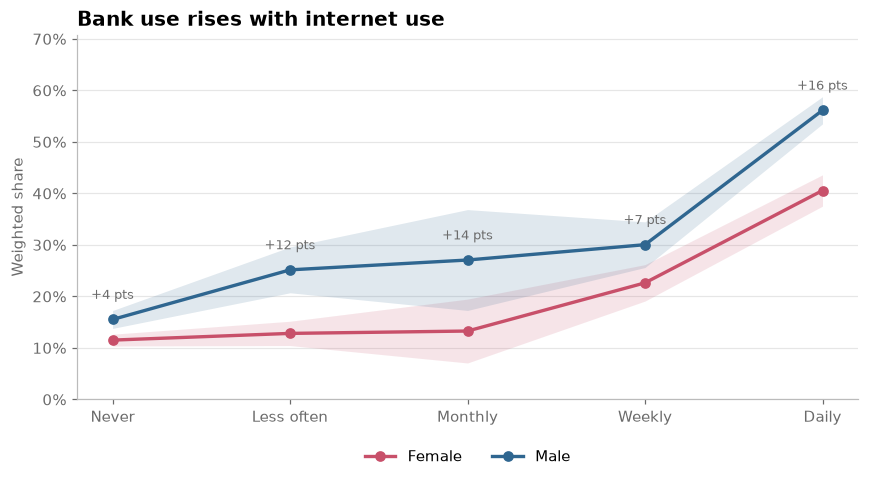

In [22]:
lines_by_gender(df, "target_bank_account", "internet_use_frequency",
                title="Bank use rises with internet use",
                xlabels=["Never", "Less often", "Monthly", "Weekly", "Daily"],
                fname=FIG / "h6_bank_by_internet_use.png")
plt.show()

**Finding:** 

Among people who own a phone, have a smartphone or use the internet daily, bank use is much higher, but so is the gender gap: 25% vs 40% for sole phone owners, 35% vs 49% for smartphone owners, and 40% vs 56% for daily internet users (gaps of 15–16 pts). 

Among people with no phone of their own, bank use is very low for both sexes (6–11%) and there is no gap. 

Women's bank use stays flat until they use the internet weekly.

Digital access is a precondition for banking, but it does not close the gender gap; it widens it. 

Men convert phones and internet use into bank accounts faster than women do.

## 3.7. Physical access: distance to the nearest provider, urban vs rural

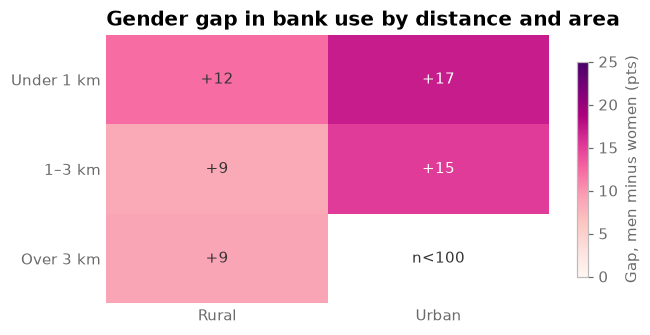

In [23]:
df["distance_band"] = pd.cut(df["distance_to_nearest_provider"], bins=[-1, 0, 2, 7],
                             labels=["Under 1 km", "1–3 km", "Over 3 km"])

heatmap_gap(df, "target_bank_account", "distance_band", "location_type",
            row_order=["Under 1 km", "1–3 km", "Over 3 km"],
            title="Gender gap in bank use by distance and area",
            fname=FIG / "h7_gap_heatmap_distance.png")
plt.show()

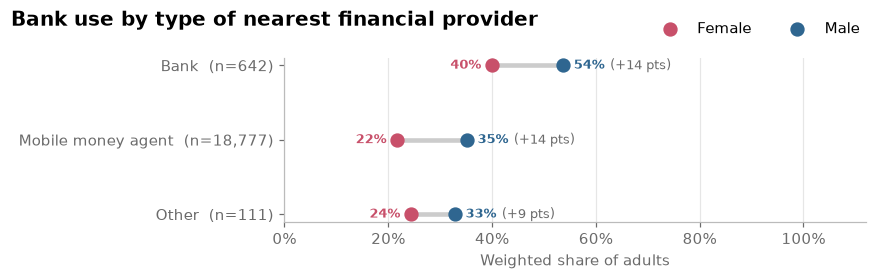

In [24]:
dumbbell_rates(df, "target_bank_account", "nearest_provider_type",
               order=["Bank", "Mobile money agent", "Other"],
               title="Bank use by type of nearest financial provider",
               fname=FIG / "h7_bank_by_nearest_provider.png")
plt.show()

**Finding:** 

Physical access does not explain the gender gap. The gap is largest where providers are closest: 17 pts in urban areas under 1 km and 15 pts at 1–3 km, compared with 9–12 pts in rural areas. 

Living near a bank raises bank use for both sexes (40% of women and 54% of men, vs 22% and 35% near a mobile money agent), but the gap stays at 14 pts. 

Distance is not the barrier for women; the gap is widest where access is easiest.

## 3.8 Regional view: the gender gap in bank use across Kenya's counties

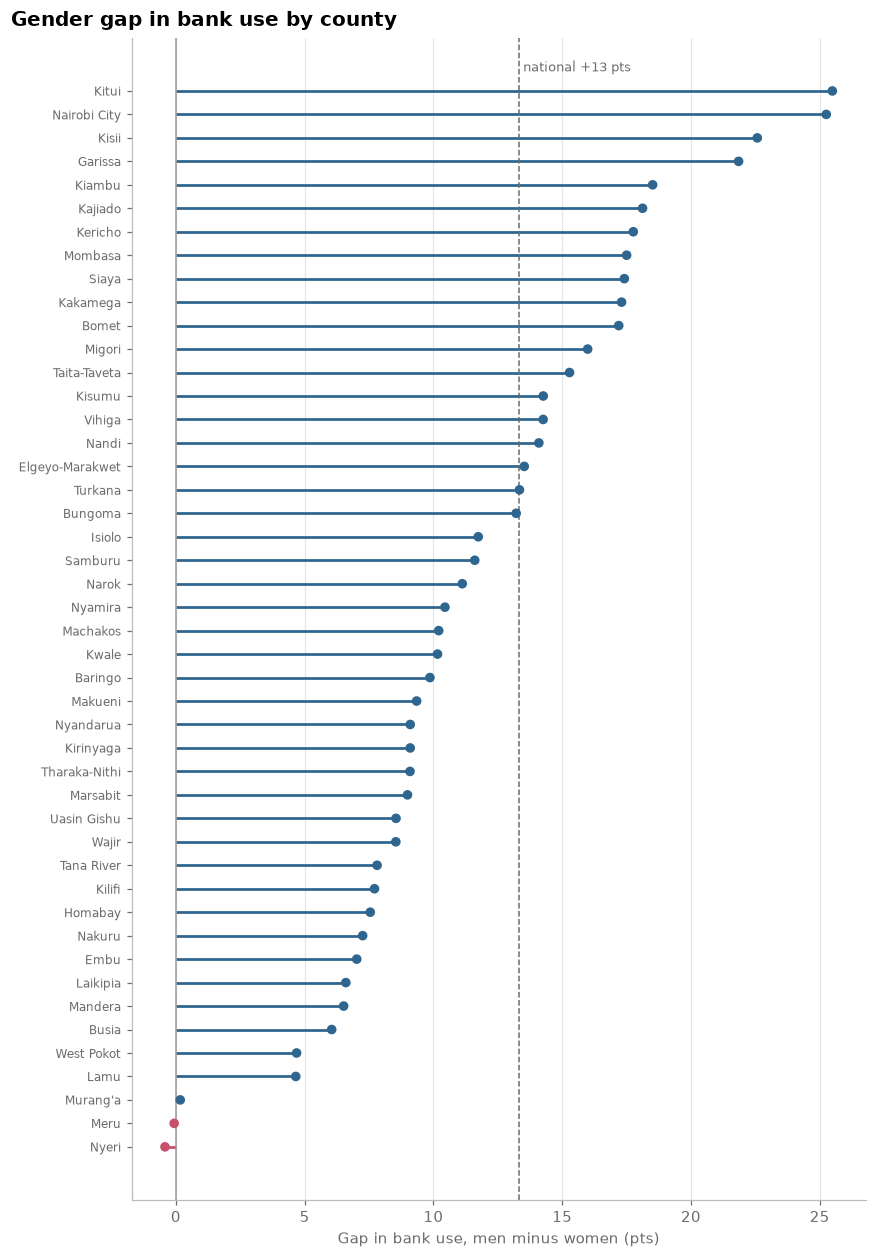

In [25]:
lollipop_gap(df, "target_bank_account", "county",
             title="Gender gap in bank use by county",
             fname=FIG / "county_gap_lollipop.png")
plt.show()

**Finding (regional):** 

The gender gap in bank use is present in 44 of 47 counties. It is largest in Kitui and Nairobi City (about 25 pts), followed by Kisii and Garissa (22–23 pts), and close to zero only in Murang'a, Meru and Nyeri, all in the Mount Kenya region. 

This matches FSD Kenya's 2024 county analysis, which also identified Kitui and Nairobi as having the largest bank gaps and Nyeri and Meru as exceptions. 

Caveat: each county has only a few hundred respondents, so individual county estimates are imprecise; the overall pattern matters more than any single ranking.

## 3.9 Statistical tests
The charts show differences; these tests check whether they are larger than chance. 

Because many tests are run at once, a **Bonferroni correction** is applied (the 0.05 threshold is divided by the number of tests). With about 20,000 respondents even tiny differences are "significant", so **effect sizes** are reported alongside p-values and are what matter for interpretation.



### 3.9.1 A/B test: do women and men differ in inclusion? (two-proportion z-test)

In [26]:


from scipy import stats

def two_proportion_ztest(yes_a, n_a, yes_b, n_b):
    """A/B test: are two proportions different? Returns z, p-value and Cohen's h (effect size)."""
    p_a, p_b = yes_a / n_a, yes_b / n_b
    p_pool = (yes_a + yes_b) / (n_a + n_b)
    se = np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
    z = (p_b - p_a) / se
    p_value = 2 * stats.norm.sf(abs(z))                          # two-sided
    h = 2 * np.arcsin(np.sqrt(p_b)) - 2 * np.arcsin(np.sqrt(p_a))  # 0.2 small, 0.5 medium, 0.8 large
    return p_a, p_b, z, p_value, h

rows = []
for target, name in [("target_formal_access", "Formal access"), ("target_bank_account", "Bank account")]:
    women = df.loc[df["gender"] == "Female", target]
    men = df.loc[df["gender"] == "Male", target]
    p_w, p_m, z, p, h = two_proportion_ztest(women.sum(), len(women), men.sum(), len(men))
    rows.append({"target": name, "women": p_w, "men": p_m, "gap_pts": (p_m - p_w) * 100,
                 "z": z, "p_value": p, "cohens_h": h})
ab = pd.DataFrame(rows).set_index("target")
ab.round(4)

,women,men,gap_pts,z,p_value,cohens_h
target,,,,,,
Formal access,0.8537,0.8614,0.7705,1.5182,0.129,0.0220
Bank account,0.2146,0.3330,11.8458,18.5748,0.000,0.2671


**Finding (A/B test, unweighted sample):**

- **Formal access: no significant gender difference.** 85.4% of women vs 86.1% of men (gap 0.8 pts; z = 1.52, p = 0.129; Cohen's h = 0.02, negligible). We cannot reject the hypothesis that women and men have equal formal access.

- **Bank account: a large, highly significant gap.** 21.5% of women vs 33.3% of men (gap 11.8 pts; z = 18.6, p < 0.001; Cohen's h = 0.27, a small-to-medium effect, more than ten times the formal-access effect).

- This confirms H1 statistically: the gender gap has closed for access but not for banking. 

### 3.9.2 Categorical features vs bank use (chi-square test of independence)


In [27]:

def cramers_v(table):
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    return np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))

TARGET = "target_bank_account"
rows = []
for col in ORDINAL + BINARY + NOMINAL:
    table = pd.crosstab(df[col], df[TARGET])                # missing values are left out
    chi2, p, dof, _ = stats.chi2_contingency(table, correction=False)
    rows.append({"feature": col, "type": "ordinal" if col in ORDINAL else "binary" if col in BINARY else "nominal",
                 "chi2": chi2, "dof": dof, "p_value": p, "cramers_v": cramers_v(table)})
chi = pd.DataFrame(rows).set_index("feature").sort_values("cramers_v", ascending=False)

alpha = 0.05 / len(chi)                                      # Bonferroni: many tests at once
chi["significant"] = chi["p_value"] < alpha
print(f"Bonferroni-corrected threshold: p < {alpha:.4f}")
chi.round(4)

Bonferroni-corrected threshold: p < 0.0016


,type,chi2,dof,p_value,cramers_v,significant
feature,,,,,,
education_level,ordinal,2882.3127,3,0.0000,0.3821,True
wealth_quintile,ordinal,2550.3215,4,0.0000,0.3597,True
internet_use_frequency,ordinal,2443.2857,4,0.0000,0.3523,True
phone_internet_capable,binary,1827.8189,1,0.0000,0.3042,True
livelihood_category,nominal,1820.2347,5,0.0000,0.3036,True
income_from_regular_job,binary,1710.5677,1,0.0000,0.2943,True
can_read_sms,binary,660.6174,1,0.0000,0.1840,True
county,nominal,665.2593,46,0.0000,0.1835,True
relationship_to_hh_head,nominal,605.3909,4,0.0000,0.1751,True


**Finding (chi-square):** 

29 of 31 categorical features are significantly associated with bank use after Bonferroni correction (p < 0.0016). Because the sample is large, significance alone says little; effect size (Cramér's V) separates strong from weak links:

- **Moderate (V ≈ 0.29–0.38):** education (0.38), wealth quintile (0.36), internet use frequency (0.35), internet-capable phone (0.30), livelihood (0.30) and regular job (0.29). These are economic and digital resources.
- **Weak (V ≈ 0.10–0.18):** SMS literacy, county, relationship to household head, urban/rural, food insecurity, phone access, land title, ID, decision-making.
- **Negligible or not significant:** marital status, family support, shocks (V < 0.05), disability (p = 0.12) and farming income (p = 0.81).

### 3.9.3 Continuous features vs bank use (Mann-Whitney U test)
Income and the count variables are strongly skewed, so the t-test's assumption of normality does not hold. 

The Mann-Whitney U test compares the two groups' rankings instead and does not need normality. 

The effect size r runs from −1 to 1 (positive = higher among bank users; 0.1 small, 0.3 medium, 0.5 large).

In [28]:
rows = []
for col in CONTINUOUS:
    users = df.loc[df[TARGET] == 1, col].dropna()
    non_users = df.loc[df[TARGET] == 0, col].dropna()
    u, p = stats.mannwhitneyu(users, non_users, alternative="two-sided")
    r = 1 - 2 * u / (len(users) * len(non_users))            # rank-biserial effect size, -1 to 1
    rows.append({"feature": col, "median_bank_users": users.median(), "median_non_users": non_users.median(),
                 "U": u, "p_value": p, "effect_size_r": -r})
mwu = pd.DataFrame(rows).set_index("feature").sort_values("effect_size_r", key=abs, ascending=False)
mwu["significant"] = mwu["p_value"] < 0.05 / len(mwu)
mwu.round(4)

,median_bank_users,median_non_users,U,p_value,effect_size_r,significant
feature,,,,,,
income_highest_month,20000.0,6500.0000,49209067.0,0.0,0.4715,True
income_last_month,12000.0,4800.0000,45874053.0,0.0,0.4653,True
income_lowest_month,6000.0,2000.0000,44222200.5,0.0,0.4503,True
household_size,3.0,4.0000,29939267.5,0.0,-0.2073,True
income_volatility,0.6,0.6667,26224015.0,0.0,-0.1367,True
num_income_sources,1.0,1.0000,42813357.0,0.0,0.1336,True
age,38.0,36.0000,41919356.0,0.0,0.1099,True
num_children,2.0,3.0000,35299352.0,0.0,-0.0654,True
num_children_under5,0.0,0.0000,35551950.5,0.0,-0.0587,True


**Finding (Mann-Whitney U):**

- **Income is the strongest continuous difference (medium-to-large effect, r ≈ 0.45–0.47).** Bank users earn a median KSh 12,000 last month vs KSh 4,800 for non-users, roughly 2.5 times as much; the same pattern holds for highest-month (KSh 20,000 vs 6,500) and lowest-month income (KSh 6,000 vs 2,000).

- **Bank users have smaller households** (median 3 vs 4; r = −0.21, small effect) and **steadier incomes** (volatility 0.60 vs 0.67; r = −0.14), consistent with salaried work.

- Age, number of income sources and number of children differ significantly but with negligible effect sizes (|r| ≤ 0.13).

- The Mann-Whitney test was used instead of the t-test because income is strongly skewed.

### 3.9.4 Proxy check: which features carry information about gender?
Gender is never a model input, but features strongly linked to gender can act as proxies and carry the gender gap into the model. Values above about 0.2 indicate a meaningful link.

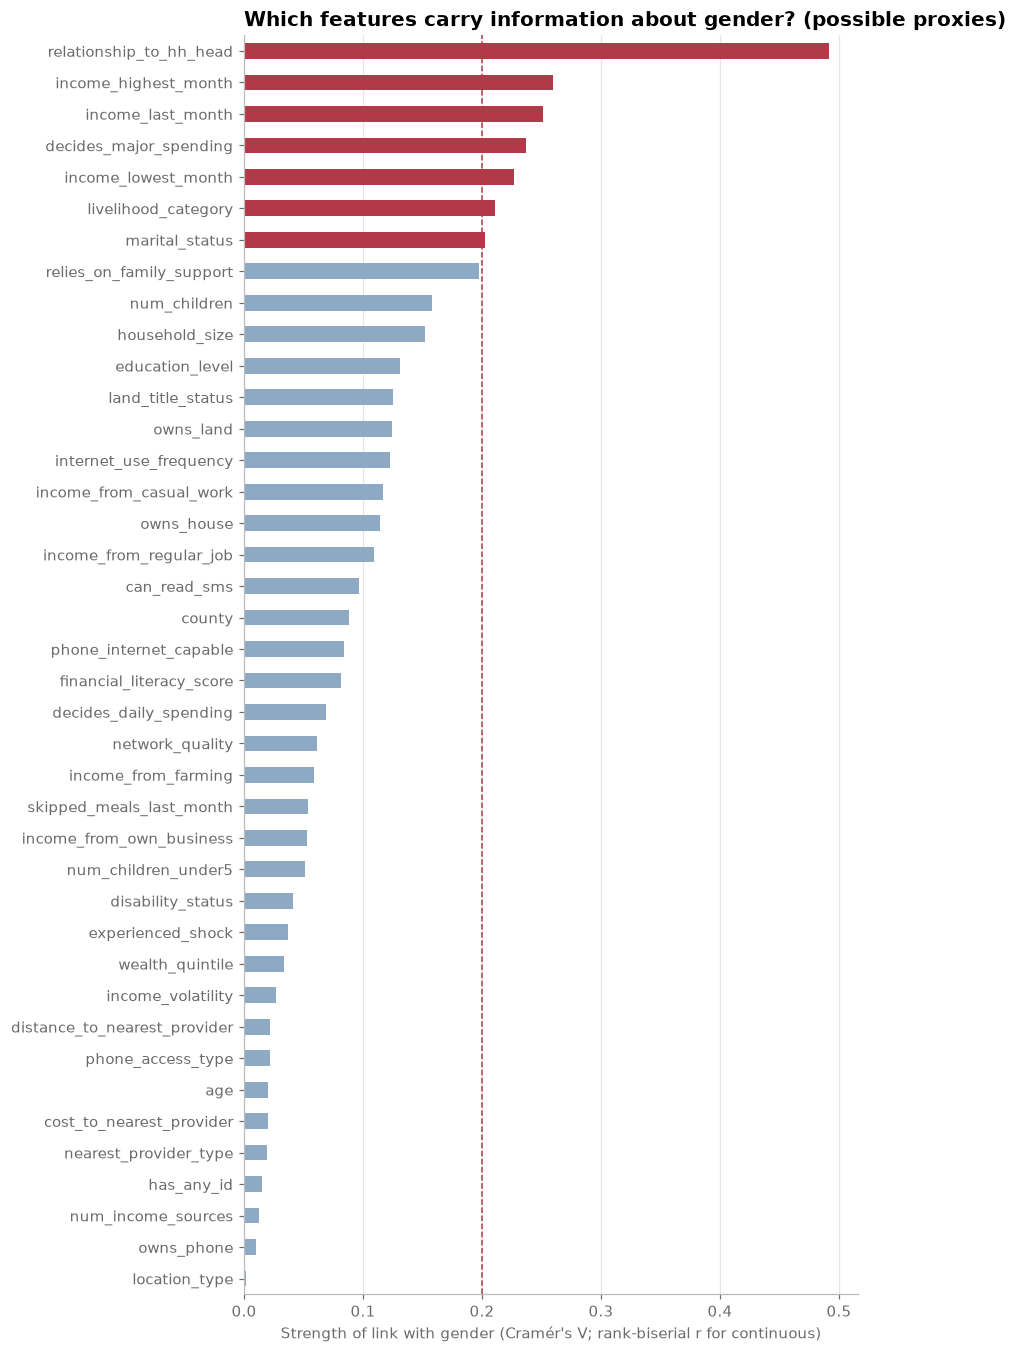

In [29]:
rows = []
for col in ORDINAL + BINARY + NOMINAL:
    rows.append({"feature": col, "cramers_v_with_gender": cramers_v(pd.crosstab(df[col], df["gender"]))})
for col in CONTINUOUS:                                         # continuous: compare women vs men
    w = df.loc[df["gender"] == "Female", col].dropna()
    m = df.loc[df["gender"] == "Male", col].dropna()
    u, _ = stats.mannwhitneyu(w, m)
    rows.append({"feature": col, "cramers_v_with_gender": abs(1 - 2 * u / (len(w) * len(m)))})
proxy = pd.DataFrame(rows).set_index("feature")["cramers_v_with_gender"].sort_values()

ax = proxy.plot.barh(figsize=(8, 0.28 * len(proxy) + 1.2),
                     color=["#B23A48" if v >= 0.2 else "#8DA9C4" for v in proxy])
ax.axvline(0.2, color="#B23A48", ls="--", lw=1)
ax.set_xlabel("Strength of link with gender (Cramér's V; rank-biserial r for continuous)")
ax.set_title("Which features carry information about gender? (possible proxies)")
ax.grid(axis="y", visible=False); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(FIG / "bi_gender_proxies.png", bbox_inches="tight"); plt.show()

**Finding (proxy check):** several features are strongly linked to gender even though gender itself is excluded from the model:

- **Relationship to household head (V = 0.49)** is by far the strongest proxy: men are mostly heads, women mostly spouses.

- **Income (r ≈ 0.23–0.26), decision-making on major spending (0.24), livelihood (0.21), marital status (0.20) and family support (0.20)** are also above the 0.2 line.
- Phone ownership, ID, urban/rural and age carry almost no gender information (< 0.03).

**Why this matters:** the features that best predict bank use (income, livelihood, education, regular job) are also linked to gender. 

A model can therefore reproduce the gender gap *through* these proxies without ever seeing gender. This is the mechanism the fairness audit in `evaluate.py` tests for, and it is why removing gender alone does not make a model fair.

## 4. Multivariate analysis
Several variables at once: which features overlap (redundancy and multicollinearity), how two drivers combine, and whether the data can be summarised in fewer dimensions (PCA).

### 4.1 Correlation between numeric features
Spearman's correlation is used because it is based on ranks, so it is not distorted by skewed income.

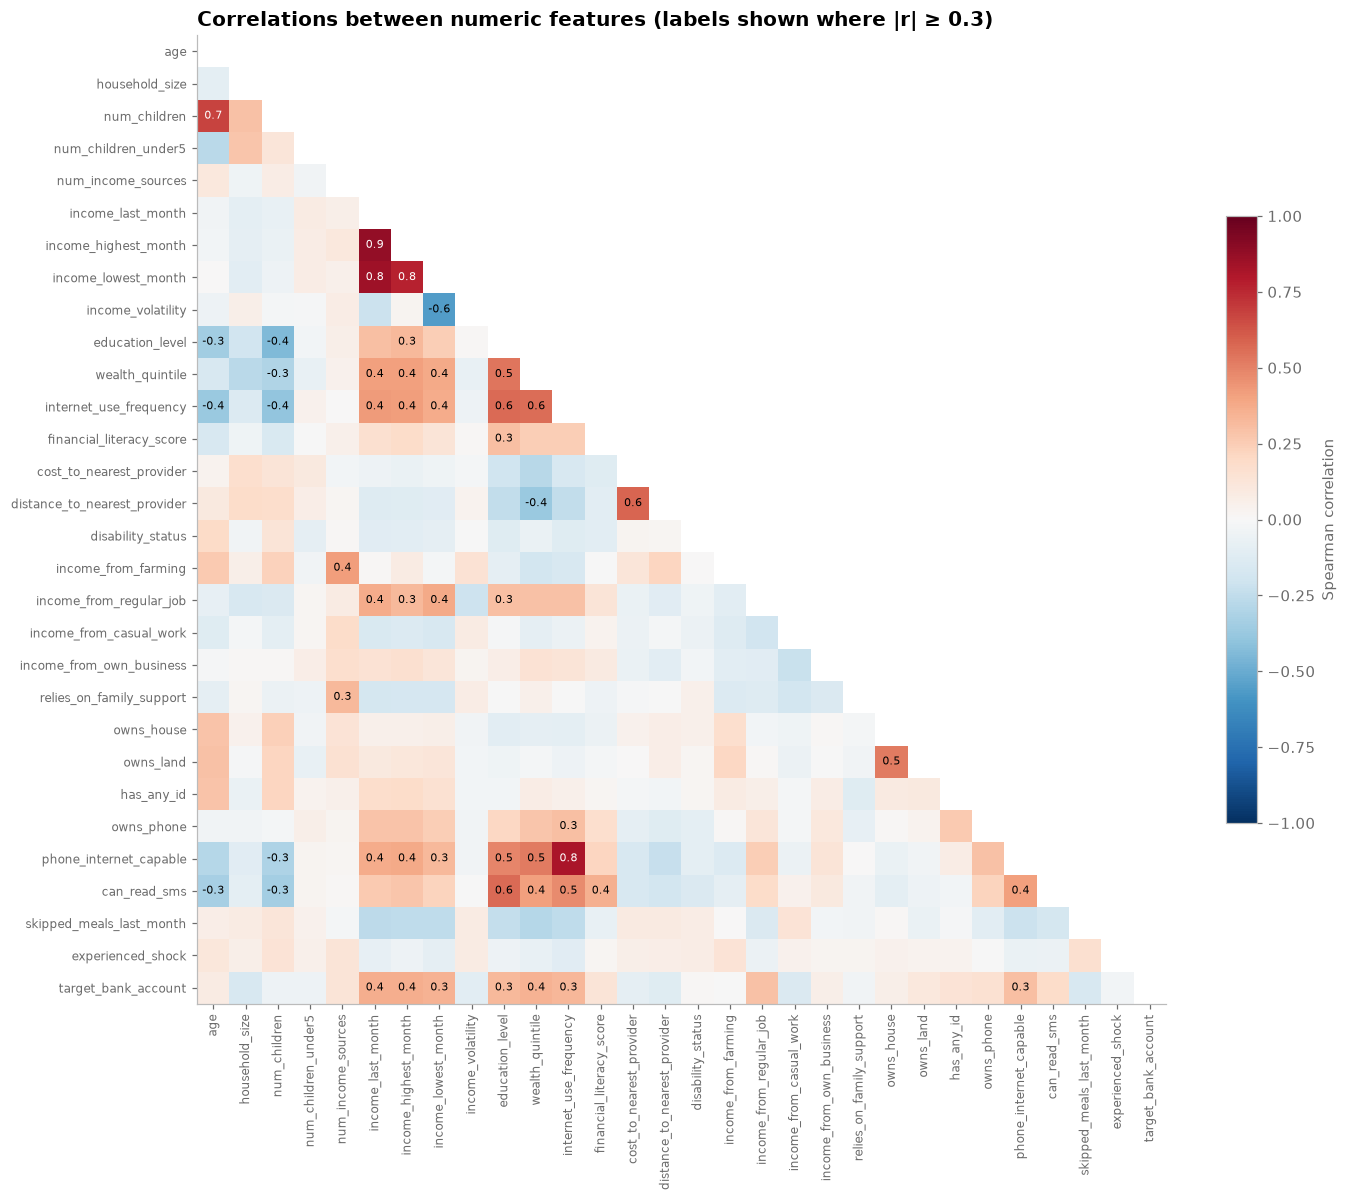

In [30]:
NUMERIC = CONTINUOUS + ORDINAL + BINARY                       # every numeric feature
corr = df[NUMERIC + ["target_bank_account"]].corr(method="spearman")   # rank-based: fine for skewed data

mask = np.triu(np.ones_like(corr, dtype=bool))               # show each pair once (lower triangle)
fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(np.ma.masked_array(corr.values, mask), cmap="RdBu_r", vmin=-1, vmax=1)
for i in range(len(corr)):
    for j in range(i):
        v = corr.values[i, j]
        if abs(v) >= 0.3:                                    # label only the meaningful ones
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(v) > 0.6 else "black")
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.6, label="Spearman correlation")
ax.set_title("Correlations between numeric features (labels shown where |r| ≥ 0.3)")
plt.tight_layout(); plt.savefig(FIG / "multi_correlation_heatmap.png", bbox_inches="tight"); plt.show()

**Finding (correlations):**
- **The three income measures are near-duplicates:** last-month, highest-month and lowest-month income correlate at 0.8–0.9. Income volatility is built from them (r = −0.6 with lowest-month income).
- **A digital-and-education cluster:** internet use frequency is very strongly linked to having an internet-capable phone (0.8) and to education (0.6) and wealth (0.6); education is also linked to SMS literacy (0.6) and wealth (0.5).
- **Other overlaps:** age and number of children (0.7), cost and distance to the nearest provider (0.6), owning a house and owning land (0.5).
- **No single feature dominates bank use:** the strongest correlations with the target are moderate (0.3–0.4 for income, wealth, education, internet use and smartphone). Bank use depends on several resources together, which is why a multivariate model is needed.

### 4.2 Multicollinearity (variance inflation factor)
VIF measures how well each feature can be predicted from all the others: VIF = 1 / (1 − R²). 

Above 5 indicates strong overlap; above 10, serious multicollinearity, which makes logistic regression coefficients unstable.

In [31]:
from sklearn.linear_model import LinearRegression

X_num = df[NUMERIC].copy()
for col in ["income_last_month", "income_highest_month", "income_lowest_month"]:
    X_num[col] = np.log1p(X_num[col])        # skewed income would distort this check (see section 5)
X_num = X_num.fillna(X_num.median())         # simple fill, for this diagnostic only

def vif(X):
    """Variance inflation factor: how well each feature is predicted by all the others.
    VIF = 1 / (1 - R²). Above 5 = high overlap; above 10 = serious multicollinearity."""
    out = {}
    for col in X.columns:
        others = X.drop(columns=col)
        r2 = LinearRegression().fit(others, X[col]).score(others, X[col])
        out[col] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(out).sort_values(ascending=False)

vifs = vif(X_num)
vifs.round(2).to_frame("VIF").head(12)

,VIF
income_highest_month,6.32
income_lowest_month,6.19
num_income_sources,4.79
income_last_month,4.65
internet_use_frequency,3.74
relies_on_family_support,3.53
income_from_farming,3.41
income_from_casual_work,3.34
phone_internet_capable,3.17
income_volatility,2.94


**Finding (multicollinearity):** 

The highest VIFs are for highest-month (6.3) and lowest-month income (6.2), followed by number of income sources (4.8, which closely tracks the income-source yes/no variables) and last-month income (4.7). 

All VIFs are below 10, so there is **no serious multicollinearity**, but the income measures overlap strongly (VIF > 5).

**Implication:** for logistic regression, redundant income measures make individual coefficients unstable (though predictions remain fine); regularisation (the tuned C in `train.py`) reduces this. Tree models are unaffected. Section 6 tests whether keeping only one income measure plus volatility loses any predictive power.

### 4.3 Two drivers together: education × wealth, by gender
Does the gender gap survive when education and wealth are held fixed at the same time?

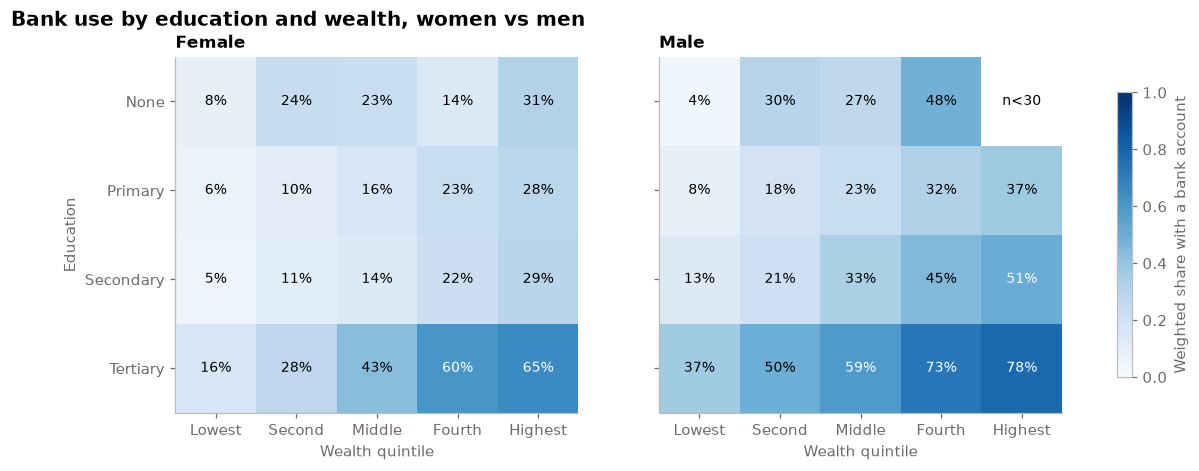

In [32]:
labels_edu = ["None", "Primary", "Secondary", "Tertiary"]
labels_wealth = ["Lowest", "Second", "Middle", "Fourth", "Highest"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, sex in zip(axes, ["Female", "Male"]):
    sub = df[df["gender"] == sex]
    rate = sub.groupby(["education_level", "wealth_quintile"]).apply(
        lambda g: np.average(g["target_bank_account"], weights=g["survey_weight"]) if len(g) >= 30 else np.nan
    ).unstack()
    im = ax.imshow(rate.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for i in range(rate.shape[0]):
        for j in range(rate.shape[1]):
            v = rate.values[i, j]
            ax.text(j, i, "n<30" if np.isnan(v) else f"{v:.0%}", ha="center", va="center", fontsize=9,
                    color="white" if (not np.isnan(v) and v > 0.5) else "black")
    ax.set_xticks(range(5), labels_wealth); ax.set_yticks(range(4), labels_edu)
    ax.set_xlabel("Wealth quintile"); ax.grid(False)
    ax.set_title(sex, fontsize=11)
axes[0].set_ylabel("Education")
fig.colorbar(im, ax=axes, shrink=0.8, label="Weighted share with a bank account")
fig.suptitle("Bank use by education and wealth, women vs men", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
plt.savefig(FIG / "multi_edu_wealth_gender.png", bbox_inches="tight"); plt.show()

**Finding (education × wealth, by gender):** 

Even when education *and* wealth are held fixed together, men bank more than women in almost every cell. The gap is largest among **secondary-educated adults in the richest quintile** (29% of women vs 51% of men, 22 pts) and among **tertiary-educated adults in the poorest quintile** (16% vs 37%). For the least educated in the poorest households, bank use is low for both sexes (4–8%).

Wealth and education also **interact**: for tertiary-educated women, bank use rises steeply with wealth (16% → 65%), but for secondary-educated women it rises only modestly (5% → 29%), while secondary-educated men reach 51%. The gender gap is therefore not explained by differences in education and wealth: at the same education and wealth level, women still bank less.

### 4.4 Principal component analysis (PCA)
PCA combines the numeric features into new uncorrelated components. 

If a few components captured most of the variation, they could replace the original features. Features are standardised first, because PCA is sensitive to scale.

29 numeric features | components for 80% of variance: 15 | for 90%: 19
PC1 explains 18.6%, PC2 9.8%


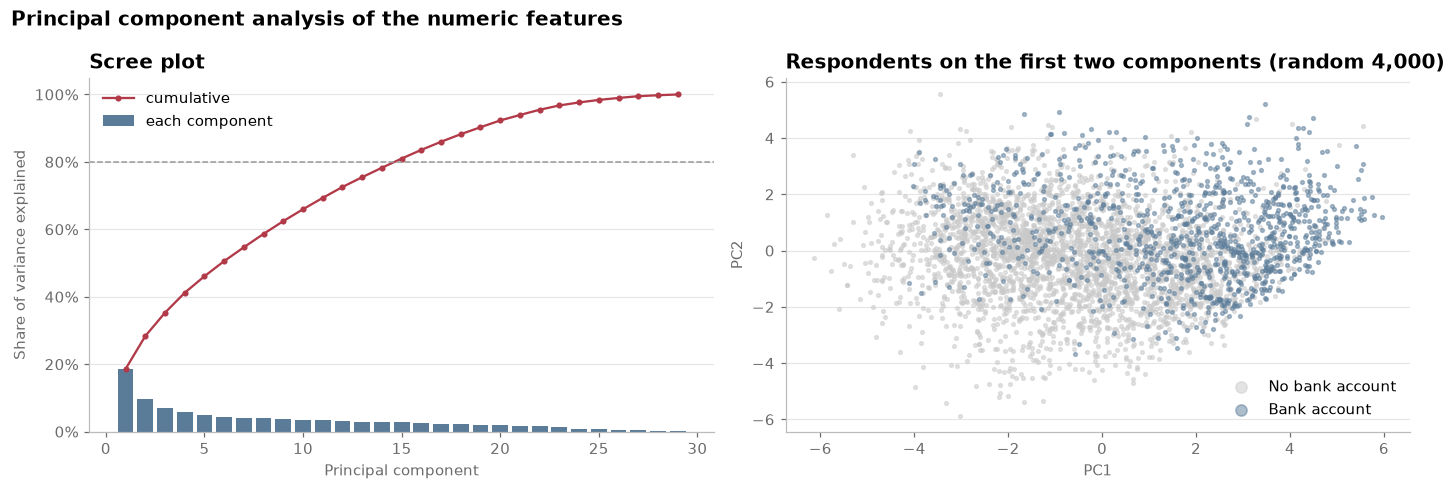

In [33]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

Z = StandardScaler().fit_transform(X_num)       # PCA needs features on the same scale
pca = PCA().fit(Z)
cum = np.cumsum(pca.explained_variance_ratio_)
n80, n90 = np.argmax(cum >= 0.80) + 1, np.argmax(cum >= 0.90) + 1
print(f"{len(NUMERIC)} numeric features | components for 80% of variance: {n80} | for 90%: {n90}")
print(f"PC1 explains {pca.explained_variance_ratio_[0]:.1%}, PC2 {pca.explained_variance_ratio_[1]:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
k = np.arange(1, len(cum) + 1)
axes[0].bar(k, pca.explained_variance_ratio_, color=NEUTRAL, label="each component")
axes[0].plot(k, cum, color="#B23A48", marker="o", ms=3, label="cumulative")
axes[0].axhline(0.8, color="#999999", ls="--", lw=1)          # 80% line
axes[0].set_xlabel("Principal component"); axes[0].set_ylabel("Share of variance explained")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].legend(); axes[0].set_title("Scree plot")

sample = np.random.default_rng(42).choice(len(Z), size=min(4000, len(Z)), replace=False)
scores = pca.transform(Z[sample])[:, :2]
y_s = df["target_bank_account"].values[sample]
for value, colour, name in [(0, "#C9C9C9", "No bank account"), (1, NEUTRAL, "Bank account")]:
    axes[1].scatter(scores[y_s == value, 0], scores[y_s == value, 1], s=6, alpha=0.5, color=colour, label=name)
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2"); axes[1].legend(markerscale=3)
axes[1].set_title("Respondents on the first two components (random 4,000)")
fig.suptitle("Principal component analysis of the numeric features", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "multi_pca.png", bbox_inches="tight"); plt.show()

**Finding (PCA):** the first component explains about 19% of the variation and the second about 10%; about 15 components are needed to retain 80% of the variation in 29 features, and about 20 for 90%. 

On the first two components, bank users concentrate on the right of PC1, so PC1 broadly captures a socioeconomic gradient, but the groups overlap heavily.

**Decision: PCA is not used for modelling.**
1. Compression is modest (29 features → about 15 components for 80% of the variation).
2. Components are blends of many features, so they cannot be interpreted. This study must explain *which* features drive predictions and any gender gap (SHAP, fairness audit), and the Data Protection Act 2019 requires individual-level reasons for automated decisions.
3. Multicollinearity is moderate (all VIF < 10) and handled by regularisation; tree models do not need decorrelated inputs.

## EDA conclusions

### Key findings
1. **The gender gap lives in banking, not in overall inclusion.** Formal access is nearly equal (84.0% of women vs 85.7% of men, weighted); the unweighted difference is not statistically significant (0.8 pts, p = 0.13). Bank account use is not: 22.5% of women vs 35.9% of men (weighted), a 13.4-point gap that is highly significant (z = 18.6, p < 0.001; Cohen's h = 0.27). Both rates reproduce the official FinAccess 2024 estimates.

2. **It is an opportunity gap.** The bank gap is near zero where almost nobody banks (poorest households, no education, no phone of one's own) and widest where banking becomes possible: 20 pts in the top wealth quintiles, 17 pts among secondary-educated adults, 15–16 pts among smartphone owners and daily internet users. As resources grow, men convert them into bank accounts faster than women.

3. **Individual resources, not household poverty, drive it.** Women and men are equal on household wealth, phone ownership and ID, but women are twice as likely to rely on family support (40% vs 21%) and less likely to have a regular job, land title, smartphone or control over spending. At equal personal income (bottom three income bands) the gap almost disappears (2–3 pts).

4. **Education and wealth together do not explain it.** Even within the same education *and* wealth group, men bank more in almost every cell, e.g. 29% of women vs 51% of men among secondary-educated adults in the richest quintile.

5. **Bank use depends on economic and digital resources.** The strongest associations are personal income (bank users earn a median KSh 12,000 vs 4,800; r ≈ 0.47), education (Cramér's V = 0.38), wealth (0.36), internet use (0.35), smartphone ownership (0.30), livelihood (0.30) and a regular job (0.29). No single feature dominates (all correlations ≤ 0.4).

6. **Several of these predictors are also linked to gender.** Relationship to household head (V = 0.49), income (0.23–0.26), decision-making (0.24), livelihood (0.21) and marital status (0.20) carry gender information. A model can therefore reproduce the gender gap through these proxies even without gender as an input.

7. **The gap is national.** Men bank more in 44 of 47 counties; the gap is largest in Kitui and Nairobi (about 25 pts) and near zero only in Murang'a, Meru and Nyeri.

### Implications for data preparation and modelling
- **Target:** bank account use is the main modelling and fairness target; formal access, which is near-equal and dominated by phone ownership, is a benchmark only.
- **Leakage:** only `mobile_money_access` is excluded (V = 0.67 with formal access; it is part of the target's definition). For bank use, no feature exceeds V = 0.4, so the feature set is leakage-free. Phone ownership and ID are strong but legitimate preconditions and are kept.
- **Class imbalance:** bank use is mildly imbalanced (26% yes, ratio 2.8 : 1). Models are compared on PR-AUC (chance baseline 0.26) rather than accuracy, and imbalance is handled by moving the decision threshold on calibrated probabilities rather than by resampling.
- **Transformation:** income is heavily right-skewed (skewness about 5, mean about twice the median), so it is transformed inside the model pipeline (section 5); other variables are only moderately skewed and left as they are.
- **Redundancy:** the three income measures are near-duplicates (r = 0.8–0.9; VIF up to 6.3) but below the threshold for serious multicollinearity; regularisation handles this, and section 6 tests whether fewer income measures suffice.
- **Encoding:** ordered variables (education, wealth, internet use, distance, cost, financial literacy) keep their order; nominal variables are one-hot encoded with rare categories grouped.
- **PCA is not used:** 15 of 29 components are needed for 80% of the variation, and components cannot be interpreted, which this study requires to explain predictions and trace any gender gap.
- **Fairness:** because key predictors are gender proxies, the model is audited directly for gender differences in error rates (equal opportunity), using survey weights.

## 5. Data preparation decisions

### 5.1 Data leakage

**Leakage check: which variables are almost the same as the target?**

Cramér's V measures how strongly two variables are linked (0 = not at all, 1 = identical). 

A feature above about 0.5 is likely a version of the target rather than a cause of it, so it must be excluded from the model.

In [34]:
import numpy as np
from scipy.stats import chi2_contingency
from matplotlib.patches import Patch


def cramers_v(x, y):
    """Strength of link between two categorical variables: 0 = none, 1 = identical."""
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    return np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))


# columns that are not scored (ids, targets, gender, helper columns, cattle)
not_features = ["respondent_id", "cluster_id", "survey_weight", "gender", "hh_head_gender",
                "target_formal_access", "target_bank_account",
                "smartphone", "internet_use", "income_band", "distance_band",
                "num_indigenous_cattle"]


def leakage_screen(target, target_label, fname):
    """Score every feature against `target` and draw the ranked bar chart."""
    scores = {}
    for col in df.columns.drop(not_features, errors="ignore"):
        x = df[col]
        if pd.api.types.is_numeric_dtype(x) and x.nunique() > 10:
            x = pd.qcut(x, 5, duplicates="drop")      # turn numbers like income into 5 groups
        keep = x.notna()
        scores[col] = cramers_v(x[keep], df.loc[keep, target])
    scores = pd.Series(scores).sort_values()

    colors = ["#B23A48" if col == "mobile_money_access"
              else "#E0A458" if s >= 0.45
              else "#8DA9C4" for col, s in scores.items()]
    ax = scores.plot.barh(figsize=(8, 0.3 * len(scores) + 1.2), color=colors)
    ax.axvline(0.5, color="#B23A48", linestyle="--", linewidth=1)
    ax.set_title(f"Which variables are too close to {target_label}?")
    ax.set_xlabel(f"Cramér's V with {target_label} (0 = no link, 1 = identical)")
    ax.legend(handles=[Patch(color="#B23A48", label="Excluded: part of the target"),
                       Patch(color="#E0A458", label="Strong precondition: kept"),
                       Patch(color="#8DA9C4", label="Other features")],
              loc="lower right", frameon=False)
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.savefig(fname, bbox_inches="tight")
    plt.show()
    return scores

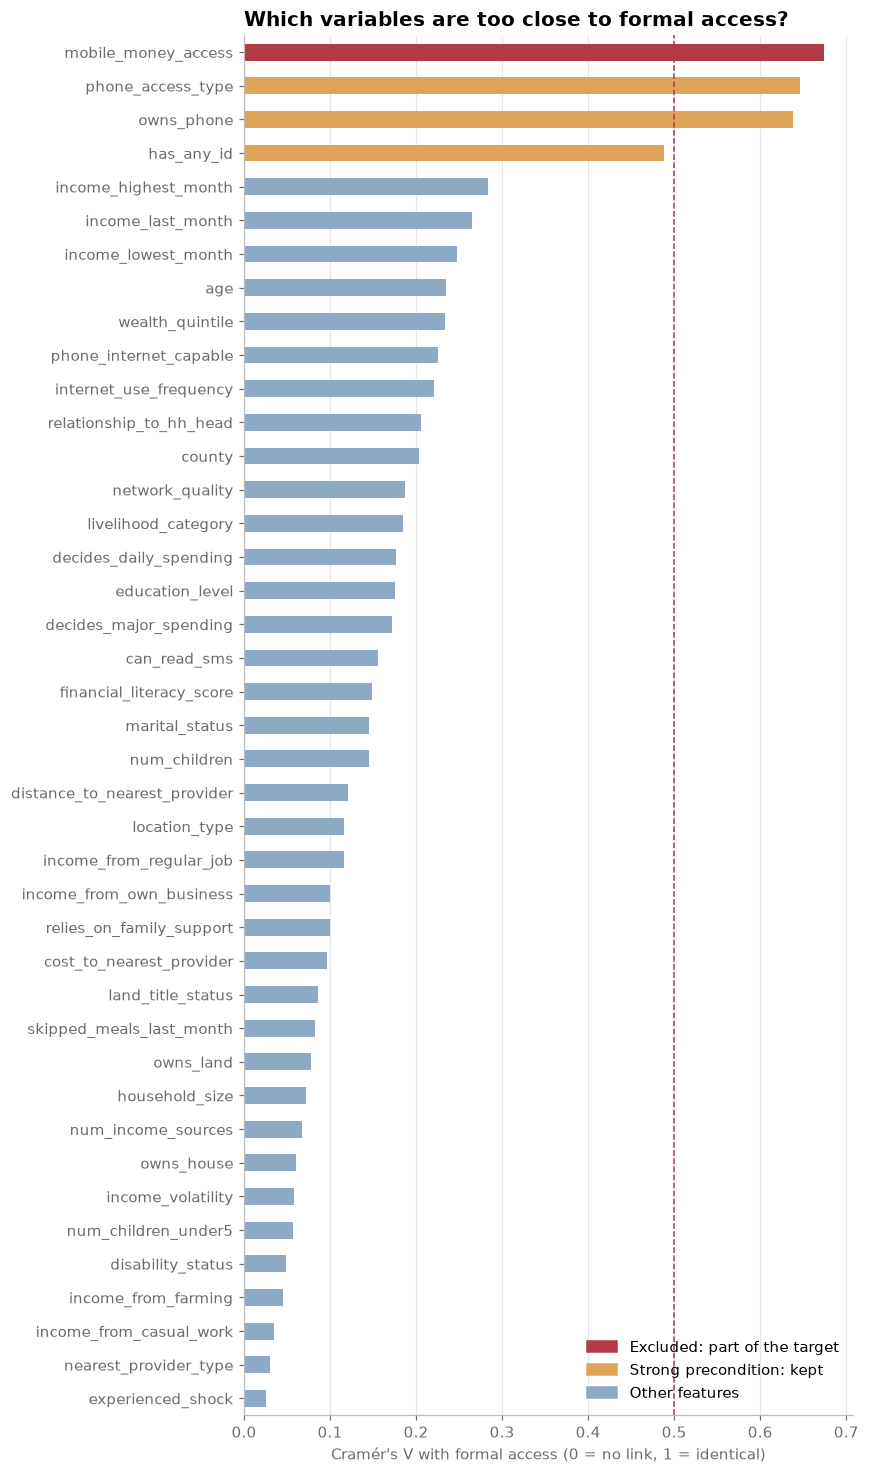

In [35]:
scores_formal = leakage_screen("target_formal_access", "formal access",
                               FIG / "h8_leakage_screen_formal.png")


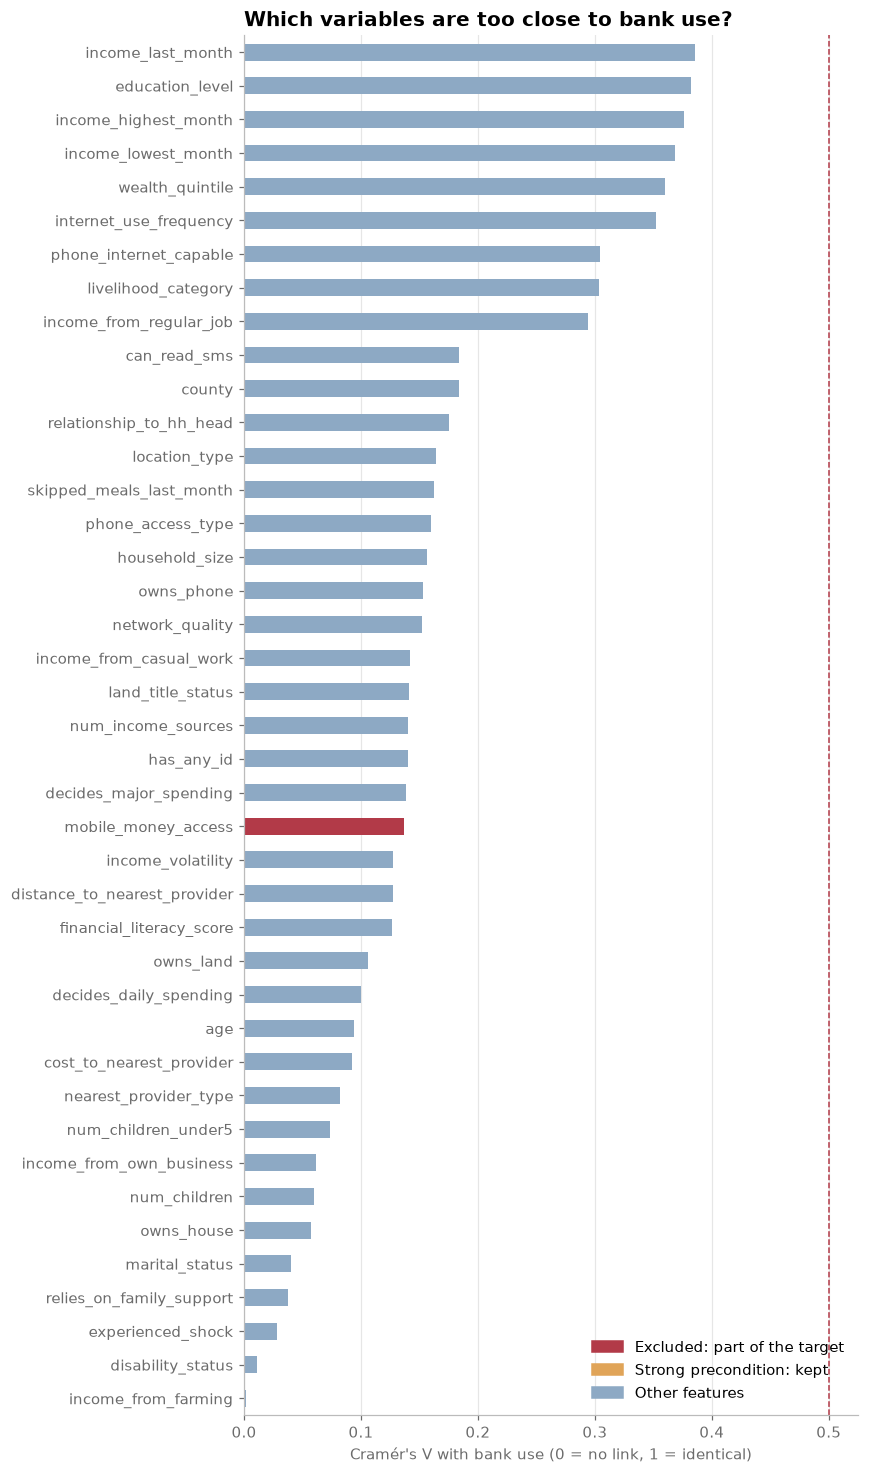

In [36]:
scores_bank = leakage_screen("target_bank_account", "bank use",
                             FIG / "h8_leakage_screen_bank.png")

**Finding:** 

For formal access, only `mobile_money_access` is true leakage (Cramér's V = 0.67), because mobile money is part of the target's definition; it is excluded. 

Phone ownership (0.64–0.65) and ID (0.49) are strong but legitimate preconditions and are kept. 

For bank use, no feature exceeds 0.4: the strongest links are personal income, education, wealth and internet use (0.35–0.39), while phone and ID fall to about 0.15.

Formal access is driven by basic access (phone, ID), where women and men are equal, while bank use is driven by economic resources (income, education, digital use), where women lag. 

This explains why the gender gap is 1.6 pts for formal access but 13.4 pts for bank use.

### 5.2 Class imbalance
Bank use is mildly imbalanced (26% yes; 2.8 "no" for every "yes")

In [37]:
from sklearn.metrics import accuracy_score

y = df["target_bank_account"]
always_no = np.zeros(len(y))                                  # a "model" that says nobody banks
print(f"Accuracy of always predicting 'no bank account': {accuracy_score(y, always_no):.1%}")
print(f"PR-AUC of a model with no skill (= share of bank users): {y.mean():.3f}")

Accuracy of always predicting 'no bank account': 73.7%
PR-AUC of a model with no skill (= share of bank users): 0.263


**Decision (class imbalance):** a useless model that always predicts "no bank account" would already be **73.7% accurate**, while its PR-AUC equals the share of bank users (**0.263**). 

Accuracy therefore hides poor performance and is not used. Instead:

1. **PR-AUC** is the main metric (no-skill baseline 0.263).
2. **Stratified folds** keep the 26% share of bank users in every fold.
3. **Threshold moving:** the decision cut-off is chosen on calibrated probabilities in `evaluate.py`, instead of the default 0.5.


### 5.3 Transformation of income
Income is strongly right-skewed (section 2.2). Four options are compared on the training rows: no transformation, log1p, Box-Cox and Yeo-Johnson.

In [38]:
from scipy import stats
from sklearn.preprocessing import PowerTransformer
from src.config import MODELS_DIR

# use training rows only: Box-Cox and Yeo-Johnson LEARN a parameter (lambda) from the data
split = pd.read_csv(MODELS_DIR / "split.csv")
train_ids = set(split.loc[split["split"] == "train", "respondent_id"].astype(str))
train_rows = df["respondent_id"].astype(str).isin(train_ids)

INCOME = ["income_last_month", "income_highest_month", "income_lowest_month"]
rows, transformed = [], {}
for col in INCOME:
    x = df.loc[train_rows, col].dropna().to_numpy().reshape(-1, 1)
    versions = {
        "none (raw KSh)": x.ravel(),
        "log1p": np.log1p(x).ravel(),
        "Box-Cox": PowerTransformer(method="box-cox", standardize=False).fit_transform(x).ravel(),
        "Yeo-Johnson": PowerTransformer(method="yeo-johnson", standardize=False).fit_transform(x).ravel(),
    }
    transformed[col] = versions
    for name, v in versions.items():
        rows.append({"variable": col, "transformation": name,
                     "skewness": stats.skew(v), "kurtosis": stats.kurtosis(v)})

result = pd.DataFrame(rows).pivot(index="transformation", columns="variable", values="skewness")
result = result.loc[["none (raw KSh)", "log1p", "Box-Cox", "Yeo-Johnson"]]
print("Skewness (0 = symmetric):")
result.round(3)

Skewness (0 = symmetric):


variable,income_highest_month,income_last_month,income_lowest_month
transformation,,,
none (raw KSh),5.139,5.030,4.362
log1p,-0.010,-0.145,-0.169
Box-Cox,0.000,0.001,-0.004
Yeo-Johnson,0.000,0.001,-0.004


**Decision (transformation):** raw income is strongly right-skewed (skewness 4.4–5.1). All three transformations remove almost all of it: log1p leaves skewness of −0.01 to −0.17, while Box-Cox and Yeo-Johnson reach about 0.00. In the Q-Q plots, raw income curves sharply away from the normal line, whereas all three transformed versions lie close to it.

**log1p is chosen.** The difference from Box-Cox and Yeo-Johnson is negligible (|skewness| < 0.2 is effectively symmetric), and log1p learns no parameter from the data, so it cannot leak information between folds; it is also easy to interpret ("income on a log scale"). It is applied to the three income measures **inside the model pipeline**, so the API can accept income in shillings.

The step pattern in the Q-Q plots comes from round-number reporting (e.g. KSh 5,000, 10,000) and the flat top at KSh 200,000 from the survey's highest reported values; neither affects this choice.

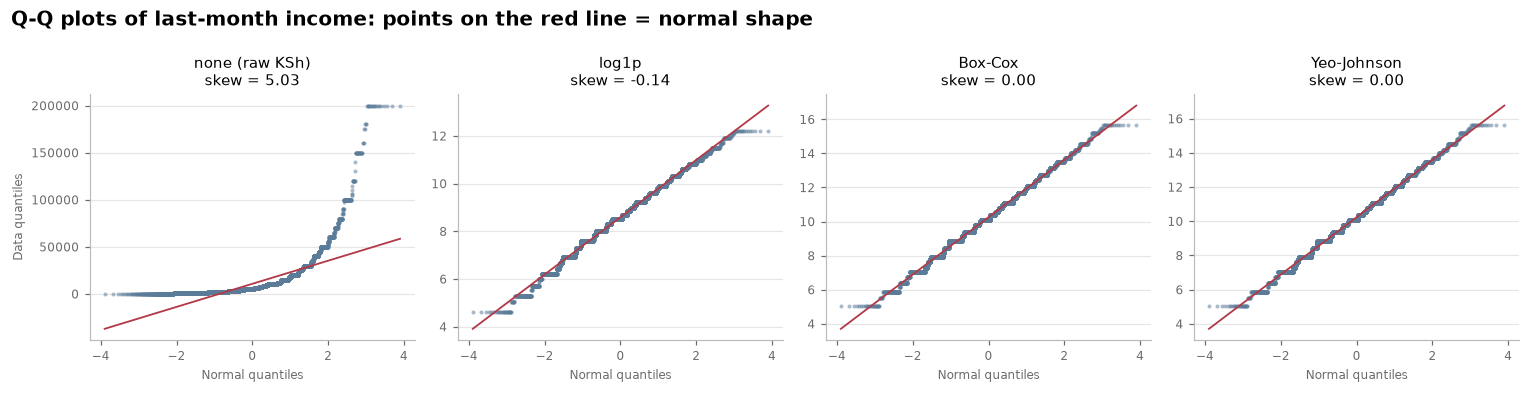

In [39]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
col = "income_last_month"
for ax, (name, v) in zip(axes, transformed[col].items()):
    (osm, osr), (slope, intercept, _) = stats.probplot(v, dist="norm")
    ax.scatter(osm, osr, s=3, alpha=0.4, color=NEUTRAL)
    ax.plot(osm, slope * osm + intercept, color="#B23A48", lw=1.2)
    ax.set_title(f"{name}\nskew = {stats.skew(v):.2f}", fontsize=9.5, fontweight="normal", loc="center")
    ax.set_xlabel("Normal quantiles", fontsize=8); ax.tick_params(labelsize=8)
axes[0].set_ylabel("Data quantiles", fontsize=8)
fig.suptitle("Q-Q plots of last-month income: points on the red line = normal shape", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "prep_income_qq.png", bbox_inches="tight"); plt.show()

### 5.4 Scaling
Logistic regression needs features on the same scale (its penalty treats all coefficients alike); tree models do not, because they split on the order of values.

In [40]:
from sklearn.preprocessing import StandardScaler

example = df.loc[train_rows, ["age", "household_size", "education_level", "income_last_month"]].dropna().copy()
example["income_last_month"] = np.log1p(example["income_last_month"])      # after the chosen transform
scaled = pd.DataFrame(StandardScaler().fit_transform(example), columns=example.columns)

pd.concat({"before scaling": example.describe().loc[["mean", "std", "min", "max"]],
           "after scaling": scaled.describe().loc[["mean", "std", "min", "max"]]}).round(2)

age  household_size  education_level  \
before scaling mean   40.48            4.08             1.48   
               std    16.44            2.45             0.91   
               min    18.00            1.00             0.00   
               max   105.00           19.00             3.00   
after scaling  mean   -0.00            0.00            -0.00   
               std     1.00            1.00             1.00   
               min    -1.37           -1.25            -1.63   
               max     3.92            6.08             1.67   

                     income_last_month  
before scaling mean               8.59  
               std                1.20  
               min                4.62  
               max               12.21  
after scaling  mean              -0.00  
               std                1.00  
               min               -3.30  
               max                3.00

**Decision (scaling):** before scaling, features are on very different scales: age has mean 40.5 and SD 16.4 (range 18–105), household size mean 4.1 and SD 2.5, education 1.5 and 0.9 (range 0–3), log income 8.6 and 1.2. 

After StandardScaler, every feature has mean 0 and SD 1, so logistic regression's penalty treats them equally. 

Scaling is applied **inside the pipeline for logistic regression only**, so means and SDs are learned from training folds; tree models are not scaled because they split on the order of values.

### 5.5 Encoding

In [41]:
from sklearn.preprocessing import OneHotEncoder

enc = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30, sparse_output=False)
nominal_train = df.loc[train_rows, NOMINAL].astype(object).fillna("UNKNOWN")
enc.fit(nominal_train)

rows = []
for col, cats, rare in zip(NOMINAL, enc.categories_, enc.infrequent_categories_):
    n_rare = 0 if rare is None else len(rare)
    rows.append({"feature": col, "categories": len(cats), "grouped as infrequent": n_rare,
                 "one-hot columns": len(cats) - n_rare + (1 if n_rare else 0)})
encoding = pd.DataFrame(rows).set_index("feature")
print(f"{len(NOMINAL)} nominal features -> {encoding['one-hot columns'].sum()} one-hot columns")
encoding

11 nominal features -> 92 one-hot columns


,categories,grouped as infrequent,one-hot columns
feature,,,
location_type,2,0,2
county,47,0,47
livelihood_category,6,0,6
marital_status,5,1,5
relationship_to_hh_head,5,0,5
decides_daily_spending,4,0,4
decides_major_spending,4,0,4
phone_access_type,5,0,5
nearest_provider_type,4,0,4


**Decision (encoding):** the 11 unordered features produce **92 one-hot columns**, most of them from county (47). Only two rare categories (fewer than 30 people) are merged into an "infrequent" group, one in marital status and one in network quality, so almost no information is lost.
- **Ordinal encoding** (ordered numbers) is used for genuinely ordered variables: education, wealth quintile, internet use frequency, financial literacy, and cost and distance to the nearest provider (done in `clean.py`).
- **Binary variables** are already 0/1.
- **One-hot encoding** is used for unordered categories, because numbering them would invent an order that does not exist. Missing values become "UNKNOWN", and unseen categories at prediction time go to the "infrequent" group, so the API does not fail.
- The encoder is fitted **inside the pipeline**, so categories are learned from training folds only.

## 6. Feature engineering and selection
**Goal:** decide which features the model should use. All work here uses the **training rows only** (the locked split saved by `train.py`), so the test set cannot influence the choice.

Because the data mixes continuous, ordinal, binary and multi-category features, the methods are chosen to handle mixed types:
- **Filter:** mutual information (captures non-linear links and works for both discrete and continuous features).
- **Wrapper:** recursive feature elimination with logistic regression, removing one *original* feature at a time (a one-hot feature such as county is kept or dropped as a whole) and scoring each step by grouped cross-validated PR-AUC.
- **Embedded:** L1 (lasso) logistic regression, which shrinks unhelpful features to exactly zero.
- **Model-based importance:** permutation importance from gradient boosting on a held-out fold. Impurity-based tree importance is avoided because it is biased towards continuous and many-category features.

In [42]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from src.config import MODELS_DIR

TARGET = "target_bank_account"
INCOME = ["income_last_month", "income_highest_month", "income_lowest_month"]

# Feature selection must only see TRAINING data: reuse the locked split saved by train.py
split = pd.read_csv(MODELS_DIR / "split.csv")
train_ids = set(split.loc[split["split"] == "train", "respondent_id"].astype(str))
tr = df[df["respondent_id"].astype(str).isin(train_ids)].copy()
print(f"Training rows used for feature selection: {len(tr):,} (test set untouched)")

# plain object dtype for text columns, so sklearn handles them reliably
tr[NOMINAL] = tr[NOMINAL].astype(object).where(tr[NOMINAL].notna(), np.nan)
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)   # grouped by village cluster


def make_model(features, model="logreg"):
    """Same preprocessing idea as train.py: impute, (log income), scale, one-hot."""
    num = [c for c in features if c not in NOMINAL]
    cat = [c for c in features if c in NOMINAL]
    inc = [c for c in num if c in INCOME]
    other = [c for c in num if c not in INCOME]
    num_steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if model == "logreg":
        num_steps.append(("scale", StandardScaler()))
    inc_steps = [("impute", SimpleImputer(strategy="median", add_indicator=True)),
                 ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"))] + ([("scale", StandardScaler())] if model == "logreg" else [])
    prep = ColumnTransformer([
        ("num", Pipeline(num_steps), other),
        ("inc", Pipeline(inc_steps), inc),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="UNKNOWN")),
                          ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30,
                                                   sparse_output=False))]), cat),
    ])
    est = (LogisticRegression(C=0.1, max_iter=2000) if model == "logreg"
           else HistGradientBoostingClassifier(learning_rate=0.1, max_leaf_nodes=15, random_state=42))
    return Pipeline([("prep", prep), ("model", est)])


def cv_pr_auc(features, model="logreg", data=None):
    data = tr if data is None else data
    s = cross_val_score(make_model(features, model), data[features], data[TARGET],
                        groups=data["cluster_id"], cv=cv, scoring="average_precision")
    return s.mean(), s.std()


BASE = CONTINUOUS + ORDINAL + BINARY + NOMINAL           # the 40 current features
print(f"Current features: {len(BASE)}")


Training rows used for feature selection: 15,808 (test set untouched)
Current features: 40


### 6.1 New features
Four features are built from existing ones, each motivated by the EDA:
- `dependency_ratio`: children per household member (care burden).
- `digital_score`: 0–3, owns a phone + has an internet-capable phone + uses the internet at least weekly.
- `has_formal_title`: holds a title deed, lease, sectional or transfer title (bank collateral).
- `regular_income`: the same income every month (volatility = 0), a sign of salaried work.

They are kept only if they improve cross-validated PR-AUC or are selected below.

In [43]:
def add_new_features(d):
    d = d.copy()
    d["dependency_ratio"] = (d["num_children"] / d["household_size"]).clip(0, 1)     # children per household member
    d["digital_score"] = (d["owns_phone"].fillna(0) + d["phone_internet_capable"].fillna(0)
                          + (d["internet_use_frequency"] >= 3).astype(int))         # 0-3: phone, smartphone, weekly internet
    d["has_formal_title"] = (d["land_title_status"] == "Formal title").astype(int)
    d["regular_income"] = (d["income_volatility"] == 0).astype(int)                  # same income every month
    return d

NEW = ["dependency_ratio", "digital_score", "has_formal_title", "regular_income"]
tr = add_new_features(tr)
print(tr[NEW].describe().T[["mean", "min", "max"]].round(2))

rows = []
for model in ["logreg", "boost"]:
    m0, s0 = cv_pr_auc(BASE, model)
    m1, s1 = cv_pr_auc(BASE + NEW, model)
    rows.append({"model": model, "PR-AUC current": f"{m0:.3f} ± {s0:.3f}",
                 "PR-AUC + new features": f"{m1:.3f} ± {s1:.3f}", "change": round(m1 - m0, 4)})
pd.DataFrame(rows).set_index("model")


                  mean  min  max
dependency_ratio  0.61  0.0  1.0
digital_score     1.72  0.0  3.0
has_formal_title  0.18  0.0  1.0
regular_income    0.06  0.0  1.0


,PR-AUC current,PR-AUC + new features,change
model,,,
logreg,0.692 ± 0.001,0.692 ± 0.001,-0.0003
boost,0.705 ± 0.003,0.704 ± 0.004,-0.0016


### 6.2 Filter method: mutual information

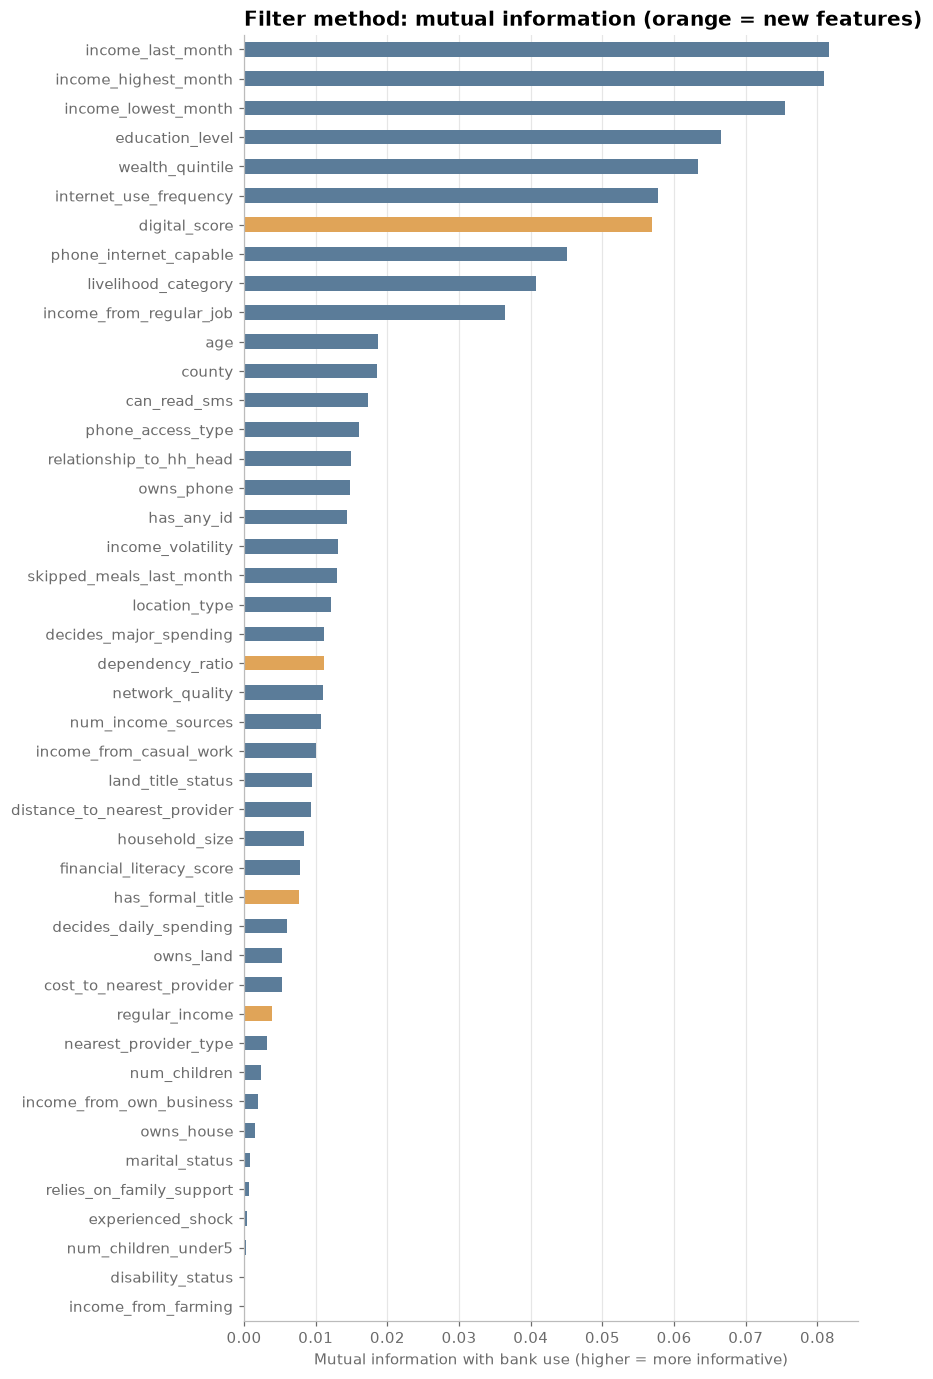

In [44]:
from sklearn.feature_selection import mutual_info_classif

ALL = BASE + NEW
X_mi = tr[ALL].copy()
for c in NOMINAL:
    X_mi[c] = X_mi[c].astype("category").cat.codes          # categories -> integer codes (-1 = missing)
X_mi = X_mi.fillna(X_mi.median(numeric_only=True))
discrete = [c not in CONTINUOUS + ["dependency_ratio"] for c in ALL]   # MI treats discrete and continuous differently

mi = pd.Series(mutual_info_classif(X_mi, tr[TARGET], discrete_features=discrete, random_state=42),
               index=ALL).sort_values()

ax = mi.plot.barh(figsize=(8, 0.26 * len(mi) + 1.2), color=[NEUTRAL if c not in NEW else "#E0A458" for c in mi.index])
ax.set_xlabel("Mutual information with bank use (higher = more informative)")
ax.set_title("Filter method: mutual information (orange = new features)")
ax.grid(axis="y", visible=False); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(FIG / "fs_mutual_information.png", bbox_inches="tight"); plt.show()



### 6.3 Wrapper method: recursive feature elimination (RFE)
Starting from all features, the weakest feature (smallest summed logistic regression coefficient) is removed at each step and PR-AUC is re-estimated by grouped cross-validation. The cut-off is the **fewest features whose PR-AUC is within one SD of the best**. This takes a few minutes.

Best PR-AUC 0.693 with 27 features; fewest features within 1 SD of best: 23


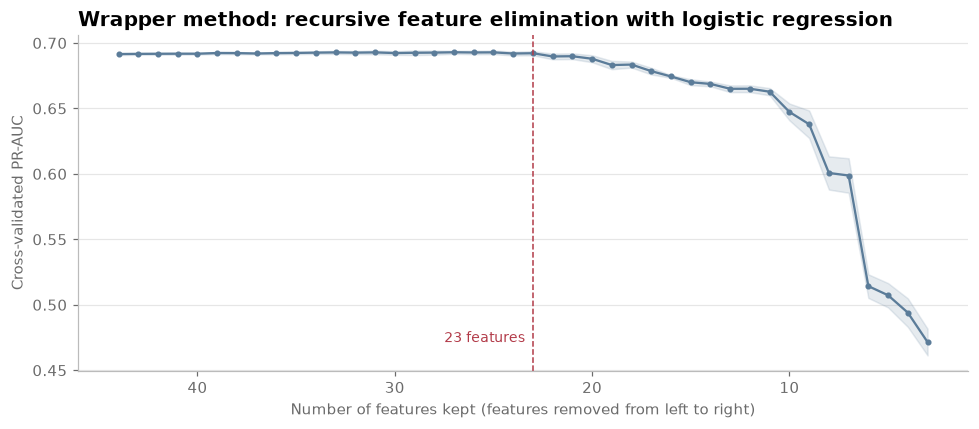

In [45]:
def group_importance(fitted, features):
    """Size of logistic regression coefficients, summed back to each original feature
    (a one-hot feature such as county has many coefficients)."""
    names = [n.split("__", 1)[1] for n in fitted.named_steps["prep"].get_feature_names_out()]
    coefs = np.abs(fitted.named_steps["model"].coef_[0])
    imp = {}
    for f in features:
        if f in NOMINAL:      # one-hot columns are named e.g. county_Nairobi City
            hits = [i for i, n in enumerate(names) if n.startswith(f + "_")]
        else:                 # the feature itself plus its "was missing" flag
            hits = [i for i, n in enumerate(names) if n in (f, f"missingindicator_{f}")]
        imp[f] = coefs[hits].sum() if hits else 0.0
    return pd.Series(imp)

remaining, path = list(ALL), []
while len(remaining) >= 3:
    score, sd = cv_pr_auc(remaining, "logreg")
    fitted = make_model(remaining, "logreg").fit(tr[remaining], tr[TARGET])
    weakest = group_importance(fitted, remaining).idxmin()
    path.append({"n_features": len(remaining), "pr_auc": score, "sd": sd, "dropped_next": weakest})
    remaining.remove(weakest)
rfe = pd.DataFrame(path)

best = rfe.loc[rfe["pr_auc"].idxmax()]
smallest_ok = rfe[rfe["pr_auc"] >= best["pr_auc"] - best["sd"]]["n_features"].min()   # fewest features within 1 SD
print(f"Best PR-AUC {best['pr_auc']:.3f} with {int(best['n_features'])} features; "
      f"fewest features within 1 SD of best: {smallest_ok}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(rfe["n_features"], rfe["pr_auc"], color=NEUTRAL, marker="o", ms=3)
ax.fill_between(rfe["n_features"], rfe["pr_auc"] - rfe["sd"], rfe["pr_auc"] + rfe["sd"], color=NEUTRAL, alpha=0.15)
ax.axvline(smallest_ok, color="#B23A48", ls="--", lw=1)
ax.text(smallest_ok, rfe["pr_auc"].min(), f"{smallest_ok} features  ", color="#B23A48", fontsize=9, ha="right")
ax.invert_xaxis()
ax.set_xlabel("Number of features kept (features removed from left to right)")
ax.set_ylabel("Cross-validated PR-AUC")
ax.set_title("Wrapper method: recursive feature elimination with logistic regression")
plt.tight_layout(); plt.savefig(FIG / "fs_rfe_curve.png", bbox_inches="tight"); plt.show()

rfe_order = {f: i for i, f in enumerate(rfe["dropped_next"])}        # 0 = dropped first (least useful)
rfe_keep = set(ALL) - set(rfe["dropped_next"].iloc[:len(ALL) - smallest_ok])


### 6.4 Embedded method: L1 (lasso) logistic regression

In [46]:
from sklearn.model_selection import GridSearchCV

l1 = make_model(ALL, "logreg")
l1.set_params(model=LogisticRegression(penalty="l1", solver="liblinear", max_iter=2000))
search = GridSearchCV(l1, {"model__C": [0.003, 0.01, 0.03, 0.1, 0.3]}, scoring="average_precision",
                      cv=cv, n_jobs=1).fit(tr[ALL], tr[TARGET], groups=tr["cluster_id"])
print(f"Best L1 strength C = {search.best_params_['model__C']} (smaller C = stronger penalty, more zeros)")
l1_imp = group_importance(search.best_estimator_, ALL)
l1_zero = set(l1_imp[l1_imp == 0].index)
print(f"Features shrunk to exactly zero by L1: {sorted(l1_zero) if l1_zero else 'none'}")


c:\Users\maken\Documents\Strathmore Graduate Studies\DSA 8401 - Applied Machine Learning in Data Science\Assignments\Capstone Project\finaccess-fairness\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\maken\Documents\Strathmore Graduate Studies\DSA 8401 - Applied Machine Learning in Data Science\Assignments\Capstone Project\finaccess-fairness\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\maken\Documents\Strathmore Graduate Stud

Best L1 strength C = 0.3 (smaller C = stronger penalty, more zeros)
Features shrunk to exactly zero by L1: ['digital_score']


### 6.5 Model-based importance: permutation importance (gradient boosting)

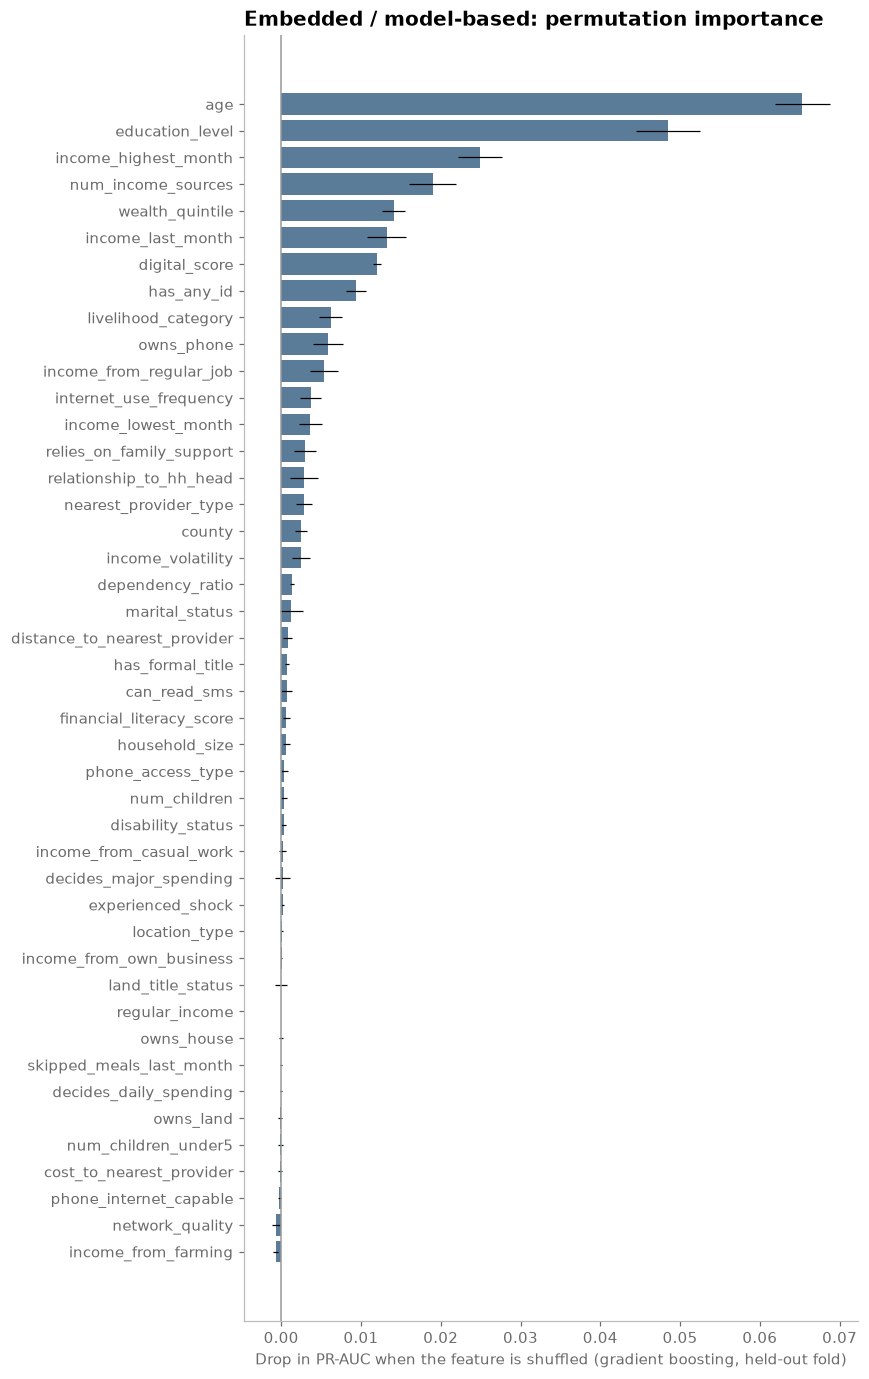

In [47]:
from sklearn.inspection import permutation_importance

# Permutation importance on a held-out fold: shuffle one ORIGINAL column at a time and see how much
# PR-AUC drops. Unlike impurity-based tree importance, it is not biased towards continuous or
# many-category features, which matters for this mixed survey data.
fit_idx, val_idx = next(cv.split(tr, tr[TARGET], groups=tr["cluster_id"]))
boost = make_model(ALL, "boost").fit(tr.iloc[fit_idx][ALL], tr.iloc[fit_idx][TARGET])
perm = permutation_importance(boost, tr.iloc[val_idx][ALL], tr.iloc[val_idx][TARGET],
                              scoring="average_precision", n_repeats=5, random_state=42, n_jobs=1)
perm_imp = pd.Series(perm.importances_mean, index=ALL).sort_values()
perm_sd = pd.Series(perm.importances_std, index=ALL)[perm_imp.index]

fig, ax = plt.subplots(figsize=(8, 0.26 * len(perm_imp) + 1.2))
ax.barh(perm_imp.index, perm_imp.values, xerr=perm_sd.values, color=NEUTRAL, error_kw={"lw": 0.8})
ax.axvline(0, color="#999999", lw=1)
ax.set_xlabel("Drop in PR-AUC when the feature is shuffled (gradient boosting, held-out fold)")
ax.set_title("Embedded / model-based: permutation importance")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(FIG / "fs_permutation_importance.png", bbox_inches="tight"); plt.show()


### 6.6 Decision: combine the four methods
A feature is proposed for removal only if it is weak in **at least 3 of the 4** methods. The reduced set is then checked by cross-validation: it is kept only if PR-AUC does not fall by more than its SD.

In [48]:
weak_mi = set(mi[mi < mi.quantile(0.25)].index)                      # bottom quarter by mutual information
weak_rfe = set(ALL) - rfe_keep                                       # eliminated before the RFE cut-off
weak_l1 = l1_zero                                                    # shrunk to zero by lasso
weak_perm = set(perm_imp[perm_imp <= perm_sd].index)                 # importance not above its own noise

votes = pd.DataFrame({
    "MI (filter)": [f in weak_mi for f in ALL],
    "RFE (wrapper)": [f in weak_rfe for f in ALL],
    "L1 (embedded)": [f in weak_l1 for f in ALL],
    "Permutation (model)": [f in weak_perm for f in ALL],
}, index=ALL)
votes["weak_votes"] = votes.sum(axis=1)
drop = votes[votes["weak_votes"] >= 3].index.tolist()               # weak in at least 3 of 4 methods
print("Proposed to drop (weak in >= 3 of 4 methods):", drop)
votes.sort_values("weak_votes", ascending=False).head(15)


Proposed to drop (weak in >= 3 of 4 methods): ['num_children', 'num_children_under5', 'owns_house', 'regular_income']


,MI (filter),RFE (wrapper),L1 (embedded),Permutation (model),weak_votes
num_children_under5,True,True,False,True,3
num_children,True,True,False,True,3
regular_income,True,True,False,True,3
owns_house,True,True,False,True,3
disability_status,True,True,False,False,2
owns_land,False,True,False,True,2
skipped_meals_last_month,False,True,False,True,2
phone_internet_capable,False,True,False,True,2
cost_to_nearest_provider,False,True,False,True,2
income_from_farming,True,False,False,True,2


In [49]:
FINAL = [f for f in ALL if f not in drop]
rows = []
for model in ["logreg", "boost"]:
    for name, feats in [("current 40", BASE), ("40 + new", ALL), (f"final {len(FINAL)}", FINAL)]:
        m, s = cv_pr_auc(feats, model)
        rows.append({"model": model, "feature set": name, "n": len(feats), "PR-AUC": round(m, 4), "SD": round(s, 4)})
pd.DataFrame(rows).pivot(index="feature set", columns="model", values="PR-AUC")


model,boost,logreg
feature set,,
40 + new,0.7038,0.6915
current 40,0.7054,0.6918
final 40,0.7041,0.6919


In [50]:
# Final decision: the new features added nothing (6.1), so none are kept;
# drop the original features that were weak in at least 3 of the 4 methods.
FINAL = [f for f in BASE if f not in drop]

rows = []
for model in ["logreg", "boost"]:
    for name, feats in [("current 40", BASE), (f"final {len(FINAL)}", FINAL)]:
        m, s = cv_pr_auc(feats, model)
        rows.append({"model": model, "feature set": name, "PR-AUC": round(m, 4), "SD": round(s, 4)})
print(pd.DataFrame(rows).pivot(index="feature set", columns="model", values=["PR-AUC", "SD"]))

import json
selection = {"final_features": FINAL, "dropped": [f for f in BASE if f not in FINAL], "new_features": []}
(REPORTS_DIR / "selected_features.json").write_text(json.dumps(selection, indent=2))
print(f"Saved {len(FINAL)} features to reports/selected_features.json")

             PR-AUC              SD        
model         boost  logreg   boost  logreg
feature set                                
current 40   0.7054  0.6918  0.0033  0.0008
final 37     0.7044  0.6915  0.0033  0.0008
Saved 37 features to reports/selected_features.json


**Finding (feature engineering and selection):**
- **New features did not help.** Adding a dependency ratio, a digital access score, a formal-title flag and a regular-income flag changed cross-validated PR-AUC by −0.0003 (logistic regression) and −0.0016 (gradient boosting), within the fold-to-fold variation. The digital score was informative on its own (mutual information 0.057) but redundant with internet use and smartphone ownership, and the L1 model shrank it to zero. None of the new features is kept.

- **The methods agree on what matters:** income (all three measures), education, wealth, internet use, smartphone ownership, livelihood and regular employment rank highest by mutual information and survive RFE and L1.

- **RFE** shows PR-AUC flat at about 0.692 from 44 down to 23 features, declining only below 20: about half the features carry almost all the predictive signal.

- **L1** chose a weak penalty (C = 0.3) and zeroed only the digital score: with 19,750 respondents there is little overfitting pressure.

- **Decision:** features weak in at least 3 of the 4 methods are dropped: number of children, number of children under five and house ownership. The final model uses **37 features**, with cross-validated PR-AUC of 0.6915 (logistic regression) and 0.7044 (gradient boosting), compared with 0.6918 and 0.7054 for all 40: both differences are within one standard deviation, so the simpler set loses nothing..

- **Kept on purpose:** marital status and family support have low predictive value but are linked to gender (section 3.9.4). They are kept so that the fairness audit can examine them, and their removal is tested separately in the robustness step.

In [52]:
import pandas as pd
from pathlib import Path

# Read your cleaned dataset
df = pd.read_parquet("data/processed/finaccess_clean.parquet")

# Save the CSV in the same folder as the Parquet file
output_path = Path("data/processed/finaccess_clean.csv")

df.to_csv(output_path, index=False)

# Show exactly where it was saved
print("File saved successfully!")
print("Location:", output_path.resolve())

File saved successfully!
Location: C:\Users\maken\Documents\Strathmore Graduate Studies\DSA 8401 - Applied Machine Learning in Data Science\Assignments\Capstone Project\finaccess-fairness\data\processed\finaccess_clean.csv
